# CS781 Phase 2. Efficient NER teacher and compact student distillation

I fine-tuned the efficient Phase 1 model as an NER teacher. To build a smaller model,
I retained the embeddings, normalization and Phase 1 blocks 5, 10 and 16, then ran
ordinary next-token recovery on the Phase 1 training caches. Both compact NER runs
started from the same recovered weights, new task heads and RNG state. The distilled
run also learned from the frozen teacher's BIO emission distributions.

The selected Phase 1 checkpoint had seen **405,811,200 input positions**. Its parent run
was named `efficient_002_mixed217m_500m` for the cumulative training budget.

| Model | Parameters with NER heads | Best epoch | Validation strict macro F1 | CodaBench strict macro F1 | Submission ID |
| --- | ---: | ---: | ---: | ---: | ---: |
| Efficient teacher | 217,966,334 | 18 | 0.4417 | 0.4235 | 976956 |
| Compact gold-only baseline | 54,258,686 | 8 | 0.3187 | | |
| Compact distilled student | 54,258,686 | 17 | 0.3256 | 0.3249 | 978111 |

I stopped teacher training after epoch 20 and selected the best checkpoint from epoch 18.
The two compact runs used different time caps and exported predictions from their best
available checkpoints. Distillation improved validation F1 by 0.0069 in this comparison.


## 1. Inputs and environment

1. Start a Kaggle notebook with two T4 GPUs and enough working space for the teacher,
   student, optimizer and cache files.
2. Attach the [efficient Phase 1 run](../phase1/phase1_efficient_500m_continuation.ipynb) with
   the selected `best_model.pt` and its protocol and sources. Set `EFFICIENT_INPUT` if
   automatic discovery is ambiguous. An extracted run, backup ZIP or split manifest
   with all companion parts can supply the weights.
3. Attach the full `prep_002_mixed16k` preparation including `caches/` for LM recovery.
   Use `PREP_INPUT` to select it explicitly. Supply the Phase 2 dataset via `PHASE2_INPUT`
   or enable Internet and provide the Kaggle secret `HF_TOKEN` for the pinned download.
4. Leave `RUN_WORKFLOW = "standard"` for a new run. Set `RESUME_INPUT` to resume from an
   extracted suite, ZIP or complete split backup in a new session.


In [1]:
%pip install -q huggingface_hub matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import json
import sys
from pathlib import Path

import numpy as np
import torch

SUITE_ID = "efficient_ner_kd_001"
PHASE1_RUN_ID = "efficient_002_mixed217m_500m"
PREPARATION_ID = "prep_002_mixed16k"

EFFICIENT_INPUT = None  # Exact run directory, best_model.pt, backup ZIP or split manifest
PREP_INPUT = None       # Full prep folder with tokenizer, manifest and official train/validation caches
PHASE2_INPUT = None     # Optional Phase_2_LNER folder or phase2_lner_data.zip
RESUME_INPUT = None     # This SUITE's backup ZIP, split manifest.json, or folder in a fresh session

ROOT = Path("/kaggle/working/cs781_phase2_efficient_kd")
SRC = Path("/kaggle/working/cs781_phase2_efficient_kd_src")
ARTIFACT_ROOT = Path("/kaggle/working")
ROOT.mkdir(parents=True, exist_ok=True)
SRC.mkdir(parents=True, exist_ok=True)

OPTIONS = {
    "suite_id": SUITE_ID, "phase1_run_id": PHASE1_RUN_ID, "preparation_id": PREPARATION_ID,
    "efficient_input": EFFICIENT_INPUT, "prep_input": PREP_INPUT,
    "phase2_input": PHASE2_INPUT, "resume_input": RESUME_INPUT,
    "hf_revision": "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e",
    "root": str(ROOT), "src": str(SRC), "artifact_root": str(ARTIFACT_ROOT),
    "selected_layers": [4, 9, 15],  # 0-based Phase 1 blocks; one-based 5/10/16
    "window_tokens": 1024, "window_overlap": 256, "validation_fraction": 0.20,
    "max_pipeline_hours": 9.0, "generate_test": True, "make_backup": True,
    "backup_part_bytes": 256 * 2**20,  # 256 MiB download parts for large suite backups
}
NER_SETTINGS = {
    "seed": 42, "epochs": 50, "minimum_epochs": 10, "patience": 8,
    "early_stop_min_delta": 0.001,
    "microbatch_size": 2, "accumulation_steps": 8, "prediction_batch_size": 2,
    "teacher_backbone_lr": 1e-5, "student_backbone_lr": 3e-5,
    "tag_head_lr": 2e-4, "boundary_head_lr": 5e-5, "crf_lr": 1e-3,
    "backbone_weight_decay": 0.01, "head_weight_decay": 0.01, "head_dropout": 0.20,
    "tag_label_smoothing": 0.0, "aux_tag_loss_weight": 0.25, "boundary_loss_weight": 0.5,
    "class_weighting": "balanced_bio", "outside_tag_weight": 0.25,
    "student_kd_weight": 0.5, "kd_temperature": 2.0, "kd_outside_weight": 0.25,
    "warmup_epochs": 1, "lr_factor": 0.5, "lr_patience": 3, "minimum_lr_fraction": 0.20,
    "gradient_clip": 1.0, "decode_mode": "crf", "trim_span_whitespace": True,
    "gradient_checkpointing": True, "save_every_minutes": 5,
    "log_every": 10, "max_run_hours": 9.0, "minimum_free_gb": 3.0,
    "maximum_skipped_updates": 20,
}
RECOVERY_SETTINGS = {
    "seed": 42, "planned_input_tokens": 30_000_000, "context_tokens": 1024,
    "microbatch_size": 2, "accumulation_steps": 4, "learning_rate": 3e-5,
    "minimum_learning_rate": 3e-6, "warmup_fraction": 0.05,
    "weight_decay": 0.01, "gradient_clip": 1.0,
    "validate_every_tokens": 1_000_000, "validation_blocks_per_source": 16,
    "save_every_minutes": 5, "max_run_hours": 9.0, "minimum_free_gb": 1.0,
    "maximum_skipped_updates": 20,
}
# Choose a subset only when its prerequisite stages already have completed outputs.
STAGES = ["teacher", "recovery", "baseline", "distilled"]

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError("Select GPU T4 x2 in Kaggle before running")
device = torch.device("cuda:0")
print("PyTorch:", torch.__version__)
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print("GPU", i, p.name, round(p.total_memory / 2**30, 1), "GiB")
print("NER effective batch:", NER_SETTINGS["microbatch_size"] * NER_SETTINGS["accumulation_steps"])
print("Suite:", SUITE_ID)

# The resume workflows are for the original saved suite with a teacher export.
RUN_WORKFLOW = "standard"
if RUN_WORKFLOW not in ("standard", "deadline_resume", "baseline_first_resume"):
    raise ValueError("Unknown workflow")


PyTorch: 2.11.0+cu128
GPU 0 Tesla T4 14.6 GiB
GPU 1 Tesla T4 14.6 GiB
NER effective batch: 16
Suite: efficient_ner_kd_001


## 2. Model, recovery and distillation implementation

The cells below write the Phase 1 backbone and BPE tokenizer, NER alignment and
decoding code, course evaluator, LM recovery trainer, teacher-logit cache and suite
driver. The driver checks source hashes and requires compatible state on resume.


In [3]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path



def split_bundle(zip_path, part_bytes=256 * 2**20, keep_zip=False):
    """Create checked .bin parts for Kaggle's output-file download buttons."""
    import shutil
    zip_path = Path(zip_path)
    if part_bytes <= 0:
        raise ValueError("Part size must be positive")
    zip_hash = sha256_file(zip_path)
    folder = zip_path.parent / (zip_path.stem + "_parts_" + zip_hash[:12])
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder / "manifest.json"
    if manifest_path.exists():
        old = read_json(manifest_path)
        if (old.get("format") == "cs781_split_zip_v1"
                and old["zip_sha256"] == zip_hash and old["part_bytes"] == part_bytes
                and bool(old["parts"])
                and sum(row["size_bytes"] for row in old["parts"]) == zip_path.stat().st_size
                and all((folder / row["name"]).is_file()
                        and (folder / row["name"]).stat().st_size == row["size_bytes"]
                        and sha256_file(folder / row["name"]) == row["sha256"]
                        for row in old["parts"])):
            if not keep_zip:
                zip_path.unlink()
            return manifest_path
    if shutil.disk_usage(folder).free < zip_path.stat().st_size + 512 * 2**20:
        raise RuntimeError("Not enough disk to split the ZIP safely. Preserve the run folder in saved outputs.")
    rows = []
    whole = hashlib.sha256()
    with open(zip_path, "rb") as source:
        number = 1
        while True:
            first = source.read(min(8 * 2**20, part_bytes))
            if not first:
                break
            part = folder / f"backup.part{number:03d}.bin"
            temporary = part.with_suffix(part.suffix + ".tmp")
            digest = hashlib.sha256()
            written = 0
            with open(temporary, "wb") as target:
                chunk = first
                while chunk:
                    target.write(chunk)
                    digest.update(chunk)
                    whole.update(chunk)
                    written += len(chunk)
                    chunk = source.read(min(8 * 2**20, part_bytes - written)) if written < part_bytes else b""
                target.flush()
                os.fsync(target.fileno())
            os.replace(temporary, part)
            rows.append({"name": part.name, "size_bytes": written, "sha256": digest.hexdigest()})
            number += 1
    if whole.hexdigest() != zip_hash:
        raise ValueError("ZIP changed while splitting; keep the ZIP and try again after training stops")
    atomic_json(manifest_path, {"format": "cs781_split_zip_v1", "zip_name": zip_path.name,
        "zip_size_bytes": zip_path.stat().st_size, "zip_sha256": zip_hash,
        "part_bytes": part_bytes, "parts": rows})
    if not keep_zip:
        zip_path.unlink()  # the same backup bytes remain in the checked parts
    return manifest_path


def reassemble_bundle(manifest_path, output_folder):
    """Restore the original ZIP with bounded RAM and verify every part."""
    manifest_path = Path(manifest_path)
    manifest = read_json(manifest_path)
    if manifest.get("format") != "cs781_split_zip_v1":
        raise ValueError("Unknown split-backup format")
    name = manifest["zip_name"]
    if Path(name).name != name:
        raise ValueError("ZIP name must be a plain filename")
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    output = output_folder / name
    if output.exists():
        if output.stat().st_size == manifest["zip_size_bytes"] and sha256_file(output) == manifest["zip_sha256"]:
            return output
        raise ValueError(f"A different file already exists: {output}")
    temporary = output.with_suffix(output.suffix + ".tmp")
    whole = hashlib.sha256()
    total = 0
    try:
        with open(temporary, "wb") as target:
            for row in manifest["parts"]:
                if Path(row["name"]).name != row["name"]:
                    raise ValueError("Part name must be a plain filename")
                part = manifest_path.parent / row["name"]
                if part.stat().st_size != row["size_bytes"]:
                    raise ValueError(f"Part size differs: {part}")
                digest = hashlib.sha256()
                with open(part, "rb") as source:
                    for chunk in iter(lambda: source.read(8 * 2**20), b""):
                        target.write(chunk)
                        whole.update(chunk)
                        digest.update(chunk)
                        total += len(chunk)
                if digest.hexdigest() != row["sha256"]:
                    raise ValueError(f"Part checksum differs: {part}")
            target.flush()
            os.fsync(target.fileno())
        if total != manifest["zip_size_bytes"] or whole.hexdigest() != manifest["zip_sha256"]:
            raise ValueError("Reassembled ZIP checksum differs")
        os.replace(temporary, output)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
    return output


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/phase1_utils.py


In [4]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/a1_tokenizer.py


In [5]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/architecture_models.py
"""Efficient causal LM: assignment GQA with actual sliding-window attention.

Course Module 2.3 pages 155-156, 167-170 and 180-185.
A3 Q2 supplies the KV-head sharing algorithm. SDPA Boolean True means allowed.
Training uses next-token targets. KV caches are inference-only.
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    architecture: str = "efficient"
    vocab_size: int = 16000
    d_model: int = 1024
    n_heads: int = 16
    n_layers: int = 16
    n_kv_heads: int = 4
    d_ff: int = 4864
    max_seq_len: int = 2560
    dropout: float = 0.1
    window_size: int = 512
    query_chunk_size: int = 128

    def __post_init__(self):
        if self.architecture != "efficient":
            raise ValueError("This notebook implements the efficient architecture only")
        assert self.d_model % self.n_heads == 0 and self.n_heads % self.n_kv_heads == 0
        assert min(self.vocab_size - 4, self.n_layers, self.d_ff, self.max_seq_len,
                   self.window_size, self.query_chunk_size) > 0
        assert 0 <= self.dropout < 1


def configuration(architecture="efficient"):
    return ModelConfig(architecture=architecture)



def positions(max_len, width):
    p = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, width, 2).float() * (-math.log(10000.0) / width))
    result = torch.zeros(max_len, width)
    result[:, 0::2] = torch.sin(p * frequency)
    result[:, 1::2] = torch.cos(p * frequency)
    return result


class Attention(nn.Module):
    def __init__(self, cfg, kv_heads=None):
        super().__init__()
        self.heads = cfg.n_heads
        self.kv_heads = cfg.n_heads if kv_heads is None else kv_heads
        assert cfg.d_model % self.heads == 0 and self.heads % self.kv_heads == 0
        self.head_dim = cfg.d_model // self.heads
        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout
        self.resid_dropout = nn.Dropout(cfg.dropout)

    def query(self, x):
        b, t, _ = x.shape
        return self.q_proj(x).view(b, t, self.heads, self.head_dim).transpose(1, 2)

    def keys_values(self, x):
        b, t, _ = x.shape
        k = self.k_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        return k, v

    def attend(self, q, k, v, allowed=None, causal=False):
        # A3 Q2: repeat each KV head for its group of query heads.
        if self.kv_heads != self.heads:
            repeats = self.heads // self.kv_heads
            k, v = k.repeat_interleave(repeats, dim=1), v.repeat_interleave(repeats, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, is_causal=causal,
            dropout_p=self.dropout if self.training else 0.0, scale=1 / math.sqrt(self.head_dim))
        b, _, t, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(b, t, -1)
        return self.resid_dropout(self.out_proj(out))

    def forward(self, x, memory=None, allowed=None, causal=False):
        k, v = self.keys_values(x if memory is None else memory)
        return self.attend(self.query(x), k, v, allowed, causal)

    def local(self, x, window, chunk, lengths=None):
        # Query tiles see only nearby keys. No full T-by-T score matrix.
        q = self.query(x)
        k, v = self.keys_values(x)
        t = x.shape[1]
        pieces = []
        for start in range(0, t, chunk):
            stop = min(t, start + chunk)
            first = max(0, start - window + 1)
            qi = torch.arange(start, stop, device=x.device)
            ki = torch.arange(first, stop, device=x.device)
            allowed = (ki[None, :] <= qi[:, None]) & (ki[None, :] > qi[:, None] - window)
            allowed = allowed[None, None, :, :]
            if lengths is not None:
                allowed = allowed & (ki[None, :] < lengths[:, None])[:, None, None, :]
            pieces.append(self.attend(q[:, :, start:stop], k[:, :, first:stop], v[:, :, first:stop], allowed))
        return torch.cat(pieces, dim=1)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(cfg.d_model, cfg.d_ff), nn.GELU(),
                                 nn.Linear(cfg.d_ff, cfg.d_model), nn.Dropout(cfg.dropout))

    def forward(self, x):
        return self.net(x)


class EfficientBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg, cfg.n_kv_heads), FeedForward(cfg)
        self.window, self.chunk = cfg.window_size, cfg.query_chunk_size

    def forward(self, x, lengths=None):
        x = x + self.attn.local(self.ln1(x), self.window, self.chunk, lengths)
        return x + self.ffn(self.ln2(x))


class BaseModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", positions(cfg.max_seq_len, cfg.d_model), persistent=False)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def initialize(self):
        for p in self.parameters():
            if p.ndim > 1:
                nn.init.xavier_uniform_(p)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def embed(self, ids, offset=None):
        t = ids.shape[1]
        p = torch.arange(t, device=ids.device)[None, :]
        if offset is not None:
            p = p + offset[:, None]
        x = self.tok_emb(ids) * math.sqrt(self.cfg.d_model) + self.pos_emb[p]
        return x


class EfficientLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.blocks = nn.ModuleList([EfficientBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, ids, lengths=None):
        if ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Input exceeds context budget")
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, lengths)
        return self.head(self.final_norm(x))

    def start_generation(self, prompt, lengths):
        x = self.embed(prompt)
        layers = []
        keep = self.cfg.window_size - 1
        indices = lengths[:, None] - keep + torch.arange(keep, device=prompt.device)[None, :]
        gather = indices.clamp_min(0)[:, None, :, None]
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            shape = (prompt.shape[0], k.shape[1], keep, k.shape[-1])
            layers.append({"k": torch.gather(k, 2, gather.expand(shape)),
                           "v": torch.gather(v, 2, gather.expand(shape))})
            x = x + block.attn.local(h, block.window, block.chunk, lengths)
            x = x + block.ffn(block.ln2(x))
        last = self.final_norm(x)[torch.arange(x.shape[0], device=x.device), lengths - 1]
        cache = {"layers": layers, "lengths": lengths, "next_positions": lengths.clone(),
                 "key_positions": indices}
        return self.head(last), cache

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"])
        key_positions = torch.cat([cache["key_positions"], cache["next_positions"][:, None]], dim=1)
        allowed = (key_positions >= 0)[:, None, None, :]
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            k, v = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
            layer["k"], layer["v"] = k[:, :, 1:], v[:, :, 1:]
        cache["key_positions"] = key_positions[:, 1:]
        cache["next_positions"] = cache["next_positions"] + 1
        return self.head(self.final_norm(x))[:, -1], cache


def select_cache(cache, indices):
    """Remove finished rows only when the active batch shrinks."""
    if isinstance(cache, torch.Tensor):
        return cache.index_select(0, indices)
    if isinstance(cache, dict):
        return {k: select_cache(v, indices) for k, v in cache.items()}
    if isinstance(cache, list):
        return [select_cache(v, indices) for v in cache]
    return cache


class ModelWithLoss(nn.Module):
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm, self.use_amp = lm, use_amp

    def forward(self, x, y, prefixes):
        # DataParallel scatters this per-example tensor along with x and y.
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits, labels = logits_and_labels(self.lm, x, y, 0)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), labels.reshape(-1))
        return loss.unsqueeze(0)


def build_model(cfg):
    return EfficientLM(cfg)


def logits_and_labels(lm, x, y, prefix_length=0):
    # y is the token immediately after each input position in x.
    return lm(x), y


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/architecture_models.py


In [6]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_data.py
"""Shared legal NER alignment, windows, and exact span decoding."""
import bisect
import hashlib
import json
import pickle
import re
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np

IGNORE = -100


def read_json(path):
    def pairs(items):
        result = {}
        for key, value in items:
            if key in result:
                raise ValueError(f"Duplicate JSON key: {key}")
            result[key] = value
        return result
    def reject(value):
        raise ValueError(f"Invalid JSON constant: {value}")
    return json.loads(Path(path).read_text(encoding="utf-8"),
                      object_pairs_hook=pairs, parse_constant=reject)


def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(2**20), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False,
                                   allow_nan=False), encoding="utf-8")
    temporary.replace(path)


class OffsetTokenizer:
    """Same byte BPE as Phase 1, retaining offsets in the unchanged string."""
    def __init__(self, state_path, manifest_path):
        self.manifest = read_json(manifest_path)
        if file_hash(state_path) != self.manifest["tokenizer_state_sha256"]:
            raise ValueError("Tokenizer bytes do not match the preparation manifest")
        with open(state_path, "rb") as f:
            saved = pickle.load(f)
        if saved["signature"] != self.manifest["tokenizer_signature"]:
            raise ValueError("Tokenizer signatures differ")
        self.signature = saved["signature"]
        self.state = saved["state"]
        self.vocab = self.state["vocab"]
        self.merges = self.state["merges"]
        self.boundary_id = self.state["boundary_id"]
        self.max_chars = max(len(piece) for piece in self.vocab)
        self.pad_id = 0

    @lru_cache(maxsize=100000)
    def encode_piece(self, piece):
        symbols = [byte + 4 for byte in piece.encode("utf-8")] + [self.boundary_id]
        while len(symbols) > 1:
            candidates = [(self.merges[(a, b)], (a, b))
                          for a, b in zip(symbols, symbols[1:])
                          if (a, b) in self.merges]
            if not candidates:
                break
            new_id, pair = min(candidates)
            merged, j = [], 0
            while j < len(symbols):
                if j + 1 < len(symbols) and (symbols[j], symbols[j+1]) == pair:
                    merged.append(new_id)
                    j += 2
                else:
                    merged.append(symbols[j])
                    j += 1
            symbols = merged
        return tuple(symbols)

    def encode(self, text):
        ids, offsets, exact_edges = [], [], []
        for match in re.finditer(r"\S+|\s+", text):
            piece = match.group()
            byte_edges = [0]
            for character in piece:
                byte_edges.append(byte_edges[-1] + len(character.encode("utf-8")))
            byte_to_char = {byte: char for char, byte in enumerate(byte_edges)}
            position = 0
            for token_id in self.encode_piece(piece):
                end = position + len(self.vocab[token_id])
                if end == position:
                    # A standalone end-of-piece marker has no character target.
                    offset = (match.start() + bisect.bisect_left(byte_edges, position),) * 2
                else:
                    offset = (match.start() + bisect.bisect_right(byte_edges, position)-1,
                              match.start() + bisect.bisect_left(byte_edges, end))
                ids.append(token_id)
                offsets.append(offset)
                exact_edges.append((position in byte_to_char, end in byte_to_char))
                position = end
            if position != byte_edges[-1]:
                raise AssertionError("BPE bytes did not cover the original piece")
        if b"".join(self.vocab[token_id] for token_id in ids).decode("utf-8") != text:
            raise AssertionError("Tokenization changed the document")
        return {"ids": np.asarray(ids, dtype=np.int64),
                "offsets": np.asarray(offsets, dtype=np.int32).reshape(-1, 2),
                "exact_edges": np.asarray(exact_edges, dtype=bool).reshape(-1, 2)}


def load_folds(root):
    root = Path(root)
    labels = [line.strip() for line in (root/"Train/labels.txt").read_text().splitlines()
              if line.strip()]
    if len(labels) != 12 or len(set(labels)) != 12:
        raise ValueError("The official label vocabulary must contain 12 unique labels")
    texts, gold, fold_ids = {}, {}, {}
    for fold in (1, 2):
        part = read_json(root/f"Train/fold{fold}-text.json")
        truth = read_json(root/f"Train/fold{fold}-gold.json")
        if set(part) != set(truth) or set(part) & set(texts):
            raise ValueError("Training document IDs are missing or duplicated across folds")
        if any(not isinstance(t, str) or not t for t in part.values()):
            raise ValueError("Training documents must be non-empty strings")
        fold_ids[fold] = sorted(part)
        texts.update(part)
        gold.update(truth)
    test = read_json(root/"Test/fold3-text.json")
    if set(test) & set(texts):
        raise ValueError("Train/test document IDs overlap")
    if any(not isinstance(t, str) for t in test.values()):
        raise ValueError("Test documents must be strings")
    # The official fold includes an empty document. Preserve its ID and predict [].
    return texts, gold, test, labels, fold_ids


def document_split(texts, gold, folds, labels, seed=42, fraction=0.2):
    # Select whole documents before windowing. No model scores enter this split.
    groups = []
    if len({hashlib.sha256(t.encode()).hexdigest() for t in texts.values()}) != len(texts):
        raise ValueError("Duplicate document texts exist; group them before splitting")
    for ids in folds.values():
        hashes = {}
        for did in ids:
            digest = hashlib.sha256(texts[did].encode()).hexdigest()
            hashes.setdefault(digest, []).append(did)
        groups.append(list(hashes.values()))
    if sum(len(g) for g in groups) != len(texts):
        raise ValueError("Duplicate training texts exist; group them across folds before splitting")
    for attempt in range(1000):
        rng = np.random.default_rng(seed + attempt)
        val = []
        for group in groups:
            order = rng.permutation(len(group))
            count = max(1, round(len(group) * fraction))
            val.extend(did for i in order[:count] for did in group[int(i)])
        train = sorted(set(texts)-set(val))
        val = sorted(val)
        present = lambda ids: {entity[2] for did in ids for entity in gold[did]}
        if present(train) == set(labels) == present(val):
            return {"train_ids": train, "validation_ids": val,
                    "seed": seed, "selection_attempt": attempt,
                    "validation_fraction": fraction}
    raise ValueError("Could not obtain a split with every label in train and validation")


def decode_spans(text, document, tag_ids, starts, ends, tag_names):
    offsets = document["offsets"]
    result, active = [], None
    def finish():
        nonlocal active
        if active is not None:
            first, last, label = active
            a = int(offsets[first, 0]) + int(starts[first])
            b = int(offsets[last, 0]) + int(ends[last])
            if 0 <= a < b <= len(text):
                result.append((a, b, label))
        active = None
    for i, (a, b) in enumerate(offsets):
        if a == b:
            continue
        name = tag_names[int(tag_ids[i])]
        if name == "O":
            finish()
            continue
        prefix, label = name.split("-", 1)
        if prefix == "B" or active is None or active[2] != label:
            finish()
            active = [i, i, label]
        else:
            active[1] = i
    finish()
    return [list(span) for span in sorted(set(result))]


def prepare_documents(texts, gold, tokenizer, labels):
    tag_names = ["O"] + [tag for label in labels for tag in ("B-"+label, "I-"+label)]
    tag_to_id = {name: i for i, name in enumerate(tag_names)}
    documents, counts, examples = {}, Counter(), []
    for did, text in texts.items():
        doc = tokenizer.encode(text)
        n = len(doc["ids"])
        a, b = doc["offsets"].T
        content = b > a
        tags = np.where(content, 0, IGNORE).astype(np.int64)
        start_y = np.full(n, IGNORE, dtype=np.int64)
        end_y = np.full(n, IGNORE, dtype=np.int64)
        spans = sorted(gold.get(did, []), key=lambda e: (e[0], e[1], e[2]))
        previous_end = -1
        for entity in spans:
            begin, end, label = entity[:3]
            if (type(begin) is not int or type(end) is not int or
                    not 0 <= begin < end <= len(text) or label not in labels):
                raise ValueError(f"Invalid gold entity in {did}: {entity}")
            if len(entity) == 4 and text[begin:end] != entity[3]:
                raise ValueError(f"Gold entity text/offset mismatch in {did}")
            if begin < previous_end:
                raise ValueError(f"Overlapping gold entities in {did}; one BIO sequence cannot encode them")
            previous_end = end
            positions = np.flatnonzero(content & (b > begin) & (a < end))
            if not len(positions) or np.any(tags[positions] != 0):
                raise ValueError(f"Two entities share a BPE prediction unit in {did}: {entity}")
            first, last = int(positions[0]), int(positions[-1])
            tags[positions] = tag_to_id["I-"+label]
            tags[first] = tag_to_id["B-"+label]
            start_y[first] = begin - int(a[first])
            end_y[last] = end - int(a[last])
            if not (0 <= start_y[first] < b[first]-a[first] and
                    1 <= end_y[last] <= b[last]-a[last]):
                raise AssertionError("Invalid intra-token boundary target")
            counts[label] += 1
            if (a[first] != begin or b[last] != end or
                    not doc["exact_edges"][first, 0] or not doc["exact_edges"][last, 1]):
                counts["boundary_refinement_needed"] += 1
                if len(examples) < 10:
                    examples.append({"document_id": did, "gold": entity,
                                     "whole_token_text": text[int(a[first]):int(b[last])]})
        doc.update(tags=tags, start_y=start_y, end_y=end_y)
        if spans:
            # Verify representability with the same decoder used at inference.
            start_oracle = np.where(start_y == IGNORE, 0, start_y)
            end_oracle = np.where(end_y == IGNORE, b-a, end_y)
            predicted = decode_spans(text, doc, np.maximum(tags, 0),
                                     start_oracle, end_oracle, tag_names)
            if {tuple(e[:3]) for e in spans} != {tuple(e) for e in predicted}:
                raise AssertionError(f"Gold-to-tags-to-spans round trip failed for {did}")
        documents[did] = doc
    report = {"documents": len(texts), "tokens": sum(len(d["ids"]) for d in documents.values()),
              "entities": sum(counts[label] for label in labels),
              "label_counts": {label: counts[label] for label in labels},
              "boundary_refinement_needed": counts["boundary_refinement_needed"],
              "examples": examples, "oracle_roundtrip": "passed"}
    return documents, tag_names, report


def make_windows(documents, ids, window_size=512, overlap=128):
    if not 0 <= overlap < window_size:
        raise ValueError("Overlap must be smaller than the window")
    windows = []
    for did in ids:
        n = len(documents[did]["ids"])
        starts = list(range(0, n, window_size-overlap))
        owner, quality = np.zeros(n, dtype=np.int32), np.full(n, -1, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            positions = np.arange(start, stop)
            score = np.minimum(positions-start, stop-1-positions)
            choose = score > quality[start:stop]
            owner[start:stop][choose] = wi
            quality[start:stop][choose] = score[choose]
        seen = np.zeros(n, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            mask = owner[start:stop] == wi
            if not mask.any():
                continue
            seen[start:stop] += mask.astype(np.int32)
            windows.append({"document_id": did, "start": start, "stop": stop,
                            "owner": mask})
        if not np.all(seen == 1):
            raise AssertionError("Window ownership must cover each position exactly once")
    return windows


def strict_metrics(gold, predictions, labels):
    if set(gold) != set(predictions):
        raise ValueError("Prediction IDs do not match the gold IDs")
    stats = {label: [0, 0, 0] for label in labels}
    for did in gold:
        g = {tuple(e[:3]) for e in gold[did]}
        p = {tuple(e[:3]) for e in predictions[did]}
        if len(p) != len(predictions[did]):
            raise ValueError("Duplicate predicted spans")
        for label in labels:
            gs, ps = {e for e in g if e[2] == label}, {e for e in p if e[2] == label}
            for i, value in enumerate((len(gs & ps), len(ps-gs), len(gs-ps))):
                stats[label][i] += value
    per_label = {}
    for label, (tp, fp, fn) in stats.items():
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
        per_label[label] = dict(precision=precision, recall=recall, f1=f1,
                                true_positive=tp, false_positive=fp, false_negative=fn)
    return {"strict_macro_f1": float(np.mean([v["f1"] for v in per_label.values()])),
            "strict_macro_precision": float(np.mean([v["precision"] for v in per_label.values()])),
            "strict_macro_recall": float(np.mean([v["recall"] for v in per_label.values()])),
            "per_label": per_label}


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_data.py


In [7]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_crf.py
"""Trainable linear-chain BIO CRF, including truncated document sections."""
import numpy as np
import torch
from torch import nn


def bio_constraints(tag_names):
    if not tag_names or tag_names[0] != "O" or len(set(tag_names)) != len(tag_names):
        raise ValueError("Expected a unique BIO vocabulary beginning with O")
    initial = np.ones(len(tag_names), dtype=bool)
    allowed = np.ones((len(tag_names), len(tag_names)), dtype=bool)
    for current, name in enumerate(tag_names):
        if name == "O":
            continue
        if not name.startswith(("B-", "I-")) or "B-" + name[2:] not in tag_names:
            raise ValueError("Invalid BIO vocabulary")
        if name.startswith("I-"):
            initial[current] = False
            allowed[:, current] = [p in ("B-" + name[2:], name) for p in tag_names]
    return initial, allowed


class LinearChainBIOCRF(nn.Module):
    """Transitions[previous, current]; NLL sums over owned content sections.

    Only actual document starts/ends use learned start/end potentials. Interior
    sections can start with I-* and have a free endpoint: a window edge is not an
    entity boundary. Zero-character markers and context-only tokens are packed
    out before calling this class. No class weights or smoothing modify the CRF
    probability distribution; balanced CE can be used as a separate auxiliary loss.
    """
    def __init__(self, tag_names):
        super().__init__()
        self.tag_names = list(tag_names)
        initial, allowed = bio_constraints(self.tag_names)
        self.register_buffer("initial_allowed", torch.from_numpy(initial), persistent=False)
        self.register_buffer("transition_allowed", torch.from_numpy(allowed), persistent=False)
        count = len(tag_names)
        self.transitions = nn.Parameter(torch.zeros(count, count))
        self.start_transitions = nn.Parameter(torch.zeros(count))
        self.end_transitions = nn.Parameter(torch.zeros(count))

    def neg_log_likelihood(self, emissions, tags, lengths, document_start, document_end):
        """Return one float32 loss per row; right-padded rows may be empty."""
        if emissions.ndim != 3 or tags.shape != emissions.shape[:2]:
            raise ValueError("CRF emissions and tags have inconsistent shapes")
        batch, steps, count = emissions.shape
        if count != len(self.tag_names) or steps < 1:
            raise ValueError("Invalid CRF sequence or tag dimension")
        if any(t.shape != (batch,) for t in (lengths, document_start, document_end)):
            raise ValueError("Invalid CRF section metadata")
        # CRF sums/logsumexp stay in float32, even when the transformer uses fp16.
        with torch.autocast(emissions.device.type, enabled=False):
            emissions = emissions.float()
            transitions = self.transitions.float().masked_fill(~self.transition_allowed, -torch.inf)
            first = self.start_transitions.float().unsqueeze(0) * document_start.unsqueeze(1)
            first = first.expand(batch, count).masked_fill(
                document_start.unsqueeze(1) & ~self.initial_allowed.unsqueeze(0), -torch.inf)
            values = first + emissions[:, 0]
            rows = torch.arange(batch, device=emissions.device)
            gold_score = first[rows, tags[:, 0]] + emissions[rows, 0, tags[:, 0]]
            for position in range(1, steps):
                candidates = values.unsqueeze(2) + transitions.unsqueeze(0)
                next_values = torch.logsumexp(candidates, dim=1) + emissions[:, position]
                valid = lengths > position
                values = torch.where(valid.unsqueeze(1), next_values, values)
                increment = transitions[tags[:, position-1], tags[:, position]]
                increment = increment + emissions[rows, position, tags[:, position]]
                gold_score = gold_score + torch.where(valid, increment, torch.zeros_like(increment))
            final = self.end_transitions.float().unsqueeze(0) * document_end.unsqueeze(1)
            log_partition = torch.logsumexp(values + final, dim=1)
            last_tags = tags[rows, (lengths-1).clamp_min(0)]
            gold_score = gold_score + final[rows, last_tags]
            losses = log_partition - gold_score
            return torch.where(lengths > 0, losses, torch.zeros_like(losses))

    def numpy_parameters(self):
        """Detached scores for document-level Viterbi; constraints are applied there."""
        return {name: getattr(self, name).detach().float().cpu().numpy().copy()
                for name in ("transitions", "start_transitions", "end_transitions")}


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_crf.py


In [8]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_utils.py
"""Shared batching, evaluation, checkpoint, and RNG utilities."""
import random
import subprocess
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from lner_data import IGNORE, strict_metrics, write_json


def collate(documents, windows, pad_id=0, labelled=True):
    size = max(w["stop"]-w["start"] for w in windows)
    shape = (len(windows), size)
    ids = np.full(shape, pad_id, dtype=np.int64)
    lengths = np.zeros(shape, dtype=np.int64)
    targets = {name: np.full(shape, IGNORE, dtype=np.int64)
               for name in ("targets", "start_targets", "end_targets")}
    for row, window in enumerate(windows):
        doc = documents[window["document_id"]]
        a, b = window["start"], window["stop"]
        n = b-a
        ids[row, :n] = doc["ids"][a:b]
        lengths[row, :n] = doc["offsets"][a:b, 1]-doc["offsets"][a:b, 0]
        if labelled:
            for key, field in (("targets", "tags"), ("start_targets", "start_y"),
                               ("end_targets", "end_y")):
                values = doc[field][a:b].copy()
                values[~window["owner"]] = IGNORE
                targets[key][row, :n] = values
    batch = {"ids": torch.from_numpy(ids), "char_lengths": torch.from_numpy(lengths)}
    if labelled:
        batch.update({key: torch.from_numpy(value) for key, value in targets.items()})
    return batch


def move(batch, device):
    return {key: value.to(device, non_blocking=device.type == "cuda")
            for key, value in batch.items()}


def make_parallel(model, device):
    model = model.to(device)
    if device.type == "cuda" and torch.cuda.device_count() > 1:
        return nn.DataParallel(model)
    return model


def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def official_evaluate(run_dir, gold, predictions, labels, evaluator_path, label_path, stem):
    directory = Path(run_dir)/"validation"
    truth_path, pred_path = directory/(stem+"_truth.json"), directory/(stem+"_predictions.json")
    write_json(truth_path, gold)
    write_json(pred_path, predictions)
    metrics = strict_metrics(gold, predictions, labels)
    result = subprocess.run([sys.executable, str(evaluator_path), "--truth", str(truth_path),
                             "--prediction", str(pred_path), "--labels", str(label_path)],
                            capture_output=True, text=True)
    (directory/(stem+"_official.txt")).write_text(result.stdout+result.stderr)
    if result.returncode:
        raise RuntimeError("Official evaluation failed:\n"+result.stdout+result.stderr)
    score_line = next(line for line in result.stdout.splitlines() if line.startswith("Strict Macro-F1:"))
    if abs(float(score_line.split(":", 1)[1])-metrics["strict_macro_f1"]) > 1e-6:
        raise AssertionError("Local and official Strict Macro-F1 disagree")
    write_json(directory/(stem+"_metrics.json"), metrics)
    print(result.stdout, flush=True)
    return metrics


def atomic_save(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix+".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(saved):
    random.setstate(saved["python"])
    np.random.set_state(saved["numpy"])
    torch.set_rng_state(saved["torch"])
    if saved["cuda"] and torch.cuda.is_available():
        if len(saved["cuda"]) != torch.cuda.device_count():
            raise ValueError("Resume with the same GPU count as the saved run")
        torch.cuda.set_rng_state_all(saved["cuda"])


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_utils.py


In [9]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_io.py
"""Find Kaggle inputs, download the selected folds, and restore NER outputs."""
import shutil
import zipfile
from pathlib import Path

from lner_data import read_json, write_json
from phase1_utils import reassemble_bundle

DATA_FILES = ["Train/fold1-text.json", "Train/fold1-gold.json",
              "Train/fold2-text.json", "Train/fold2-gold.json",
              "Train/labels.txt", "Test/fold3-text.json"]


def unique(paths, description):
    paths = sorted(set(Path(p).resolve() for p in paths))
    if not paths:
        raise FileNotFoundError(f"Cannot find {description}. Set its input path in the configuration cell")
    if len(paths) > 1:
        raise ValueError(f"Multiple matches for {description}. Set the exact path:\n"+
                         "\n".join(str(p) for p in paths))
    return paths[0]


def find_preparation(explicit, preparation_id):
    if explicit:
        p = Path(explicit)
        root = p.parent if p.name == "tokenizer_state.pkl" else p
        if (root/"tokenizer_state.pkl").exists() and (root/"cache_manifest.json").exists():
            return root
        candidates = [p.parent for p in root.rglob("tokenizer_state.pkl")
                      if p.parent.name == preparation_id]
    else:
        candidates = []
        for root in (Path("/kaggle/input"), Path("/kaggle/working/cs781_phase1/preparation")):
            if root.exists():
                candidates.extend(p.parent for p in root.rglob("tokenizer_state.pkl")
                                  if p.parent.name == preparation_id)
    return unique(candidates, "the matching Phase 1 preparation folder")


def find_phase1_checkpoint(explicit, run_id, working_root):
    """Accept a run, best_model.pt, backup ZIP, or checked split-ZIP manifest."""
    if explicit:
        root = Path(explicit)
        if not root.exists():
            raise FileNotFoundError(f"Phase 1 input does not exist: {root}")
        if root.is_file() and root.suffix == ".pt":
            return root
        if root.is_file() and root.suffix == ".json":
            return extract_split_phase1(root, run_id, working_root)
        if root.is_file() and zipfile.is_zipfile(root):
            return extract_phase1_checkpoint(root, run_id, working_root)
        if (root / "best_model.pt").is_file():
            return root / "best_model.pt"
    else:
        root = Path("/kaggle/input")
    candidates = [p for p in root.rglob("best_model.pt") if p.parent.name == run_id]
    if candidates:
        return unique(candidates, "the efficient-model best_model.pt")
    archives = list(root.rglob(run_id + "_backup.zip"))
    if archives:
        return extract_phase1_checkpoint(unique(archives, "the Phase 1 run backup"),
                                         run_id, working_root)
    manifests = []
    for path in root.rglob("manifest.json"):
        try:
            row = read_json(path)
        except (ValueError, OSError):
            continue
        if row.get("format") == "cs781_split_zip_v1" and row.get("zip_name") == run_id + "_backup.zip":
            manifests.append(path)
    if manifests:
        return extract_split_phase1(unique(manifests, "the checked Phase 1 split backup"),
                                    run_id, working_root)
    raise FileNotFoundError(
        f"Cannot find {run_id}/best_model.pt. Set EFFICIENT_INPUT to the checkpoint, backup, or split manifest.")


def extract_split_phase1(manifest_path, run_id, working_root):
    manifest = read_json(manifest_path)
    if manifest.get("zip_name") != run_id + "_backup.zip":
        raise ValueError("The split backup belongs to a different Phase 1 run")
    folder = Path(working_root) / "phase1_archive"
    folder.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(folder).free < manifest["zip_size_bytes"] + 2 * 2**30:
        raise RuntimeError("Not enough working space to reassemble the backup and extract best_model.pt")
    archive_path = reassemble_bundle(manifest_path, folder)
    checkpoint = extract_phase1_checkpoint(archive_path, run_id, working_root)
    archive_path.unlink()  # Preserve original input parts; retain only the needed checkpoint.
    return checkpoint


def extract_phase1_checkpoint(archive_path, run_id, working_root):
    destination = Path(working_root) / "phase1_input" / run_id
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        matches = [n for n in archive.namelist()
                   if n.replace("\\", "/").endswith(run_id + "/best_model.pt")]
        if len(matches) != 1:
            raise ValueError("The Phase 1 ZIP must contain exactly one matching best_model.pt")
        prefix = matches[0][:-len("best_model.pt")]
        for item in archive.infolist():
            if not item.filename.startswith(prefix) or item.is_dir():
                continue
            relative = item.filename[len(prefix):]
            wanted = relative in ("best_model.pt", "model_config.json", "protocol.json",
                                  "preparation_manifest.json") or relative.startswith("sources/")
            if not wanted:
                continue
            target = (destination / relative).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Invalid Phase 1 archive path")
            if target.exists() and target.stat().st_size == item.file_size:
                continue
            if shutil.disk_usage(destination).free < item.file_size + 256 * 2**20:
                raise RuntimeError("Insufficient working space to extract the Phase 1 checkpoint")
            target.parent.mkdir(parents=True, exist_ok=True)
            temporary = target.with_suffix(target.suffix + ".tmp")
            with archive.open(item) as source, temporary.open("wb") as output:
                shutil.copyfileobj(source, output, 8 * 2**20)
            temporary.replace(target)
    return destination / "best_model.pt"


def unzip_data(archive, destination):
    destination = Path(destination)
    with zipfile.ZipFile(archive) as z:
        for relative in DATA_FILES:
            matches = [name for name in z.namelist()
                       if name.replace("\\", "/").endswith("Phase_2_LNER/"+relative)]
            if len(matches) != 1:
                raise ValueError(f"The dataset ZIP must contain one {relative}")
            if z.getinfo(matches[0]).file_size > 100*2**20:
                raise ValueError("Unexpectedly large Phase 2 file")
            target = destination/"Phase_2_LNER"/relative
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(matches[0]))
        names = [n for n in z.namelist() if Path(n).name == "download_manifest.json"]
        if len(names) == 1:
            (destination/"download_manifest.json").write_bytes(z.read(names[0]))
    return destination/"Phase_2_LNER"


def phase2_data(explicit, revision, output_dir):
    destination = Path(output_dir)/"data"
    if explicit:
        root = Path(explicit)
        if root.is_file() and zipfile.is_zipfile(root):
            return unzip_data(root, destination)
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
        candidates = [p.parent.parent for p in root.rglob("fold1-text.json")
                      if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)]
        return unique(candidates, "the Phase 2 dataset folder")
    # Reuse the files downloaded during the previous preparation step if present.
    for root in (Path("/kaggle/working/cs781_phase2_data/Phase_2_LNER"),
                 destination/"Phase_2_LNER"):
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
    input_root = Path("/kaggle/input")
    candidates = [p.parent.parent for p in input_root.rglob("fold1-text.json")
                  if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)] if input_root.exists() else []
    if candidates:
        return unique(candidates, "the Phase 2 dataset folder")
    archives = list(input_root.rglob("phase2_lner_data.zip")) if input_root.exists() else []
    if archives:
        return unzip_data(unique(archives, "the Phase 2 dataset ZIP"), destination)
    from huggingface_hub import hf_hub_download
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
    for relative in DATA_FILES:
        hf_hub_download(repo_id="Exploration-Lab/CS-781-Capstone", repo_type="dataset",
                        filename="Phase_2_LNER/"+relative, revision=revision,
                        token=token, local_dir=str(destination))
    write_json(destination/"download_manifest.json", {
        "repo_id": "Exploration-Lab/CS-781-Capstone", "revision": revision,
        "files": ["Phase_2_LNER/"+relative for relative in DATA_FILES]})
    return destination/"Phase_2_LNER"


def restore_run(explicit, run_dir, run_id):
    if not explicit:
        return
    run_dir, root = Path(run_dir), Path(explicit)
    if (run_dir/"last.pt").is_file():
        print("Using the existing working-directory NER checkpoint")
        return
    if root.is_file() and zipfile.is_zipfile(root):
        staging = run_dir.parent/"restore_input"
        staging.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(root) as archive:
            for item in archive.infolist():
                target = (staging/item.filename).resolve()
                if not target.is_relative_to(staging.resolve()):
                    raise ValueError("Invalid resume archive path")
            archive.extractall(staging)
        root = staging
    if not (root/"last.pt").is_file():
        root = unique([p.parent for p in root.rglob("last.pt") if p.parent.name == run_id],
                      "the resumable NER run")
    if root.resolve() != run_dir.resolve():
        print("Restoring NER run from", root)
        shutil.copytree(root, run_dir, dirs_exist_ok=True)


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_io.py


In [10]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/evaluate_phase2.py
#!/usr/bin/env python3
"""Local evaluator for Phase 2.

Usage:
  python evaluate_phase2.py --truth truth.json --prediction prediction.json --labels labels.txt
"""
import argparse, json, sys

class DuplicateJSONKeyError(ValueError): pass
def reject_constant(v): raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")
def pairs_no_duplicates(pairs):
    out={}; dup=[]
    for k,v in pairs:
        if k in out: dup.append(k)
        out[k]=v
    if dup: raise DuplicateJSONKeyError(f"Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.")
    return out
def load_json(path):
    with open(path,encoding='utf-8') as f:
        try: return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
        except json.JSONDecodeError as e: raise ValueError(f"Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}") from e
def labels(path):
    with open(path,encoding='utf-8') as f: xs=[x.strip() for x in f if x.strip()]
    if not xs: raise ValueError('labels.txt is empty.')
    if len(xs)!=12: raise ValueError(f'Expected 12 labels, found {len(xs)}.')
    if len(set(xs))!=len(xs): raise ValueError('labels.txt contains duplicate labels.')
    return xs
def spans(x, allowed, where):
    if x is None: return set()
    if not isinstance(x,list): raise ValueError(f'{where}: expected a list of entities.')
    out=set()
    for j,s in enumerate(x):
        if not isinstance(s,list) or len(s) not in (3,4): raise ValueError(f'{where}, entity {j}: expected [start,end,label] or [start,end,label,entity_text].')
        a,b,l=s[:3]
        if isinstance(a,bool) or not isinstance(a,int) or isinstance(b,bool) or not isinstance(b,int): raise ValueError(f'{where}, entity {j}: start/end must be integers.')
        if a<0 or b<=a: raise ValueError(f'{where}, entity {j}: require 0 <= start < end.')
        if not isinstance(l,str) or l not in allowed: raise ValueError(f'{where}, entity {j}: invalid label {l!r}.')
        if len(s)==4 and not isinstance(s[3],str): raise ValueError(f'{where}, entity {j}: entity_text must be a string.')
        t=(a,b,l)
        if t in out: raise ValueError(f'{where}, entity {j}: duplicate span {t}.')
        out.add(t)
    return out

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 2 entity predictions on your own held-out split.')
    ap.add_argument('--truth',required=True); ap.add_argument('--prediction',required=True); ap.add_argument('--labels',required=True)
    args=ap.parse_args(); truth=load_json(args.truth); pred=load_json(args.prediction); labs=labels(args.labels)
    if not isinstance(truth,dict) or not truth or not isinstance(pred,dict) or not pred: raise ValueError('Truth and prediction must be non-empty JSON objects.')
    if set(truth)!=set(pred): raise ValueError(f"ID mismatch: missing={len(set(truth)-set(pred))}, extra={len(set(pred)-set(truth))}")
    stats={l:[0,0,0] for l in labs}; allowed=set(labs)
    for did in truth:
        g=spans(truth[did],allowed,f'truth[{did}]'); p=spans(pred[did],allowed,f'prediction[{did}]')
        for l in labs:
            gs={x for x in g if x[2]==l}; ps={x for x in p if x[2]==l}
            stats[l][0]+=len(gs&ps); stats[l][1]+=len(ps-gs); stats[l][2]+=len(gs-ps)
    precisions=[]; recalls=[]; f1s=[]
    print(f'Examples: {len(truth)}')
    for l in labs:
        tp,fp,fn=stats[l]; pr=tp/(tp+fp) if tp+fp else 0; rc=tp/(tp+fn) if tp+fn else 0; f=2*pr*rc/(pr+rc) if pr+rc else 0
        precisions.append(pr); recalls.append(rc); f1s.append(f)
        print(f'{l}: P={pr:.6f} R={rc:.6f} F1={f:.6f}')
    print(f'Strict Macro-F1:        {sum(f1s)/len(f1s):.6f}')
    print(f'Strict Macro-Precision: {sum(precisions)/len(precisions):.6f}')
    print(f'Strict Macro-Recall:    {sum(recalls)/len(recalls):.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}',file=sys.stderr); sys.exit(1)


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/evaluate_phase2.py


In [11]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_decoding.py
"""Document-level BIO constraints and descriptive span-error diagnostics."""
import numpy as np
from lner_data import decode_spans
from lner_crf import bio_constraints


def constrained_tags(scores, offsets, tag_names, mode="viterbi", crf_parameters=None):
    content = np.flatnonzero(offsets[:, 1] > offsets[:, 0])
    result = np.zeros(len(offsets), dtype=np.int64)
    if not len(content):
        return result
    emissions = np.asarray(scores[content], dtype=np.float32)
    if not np.isfinite(emissions).all():
        raise ValueError("Nonfinite tag scores at inference")
    if mode == "argmax":
        result[content] = emissions.argmax(-1)
        return result
    if mode not in ("viterbi", "crf"):
        raise ValueError("decode_mode must be argmax, viterbi or crf")
    count = len(tag_names)
    initial, allowed = bio_constraints(tag_names)
    transition_scores = np.zeros((count, count), np.float32)
    start_scores = end_scores = np.zeros(count, np.float32)
    if mode == "crf":
        if crf_parameters is None:
            raise ValueError("Learned CRF decoding requires its saved parameters")
        transition_scores = np.asarray(crf_parameters["transitions"], np.float32)
        start_scores = np.asarray(crf_parameters["start_transitions"], np.float32)
        end_scores = np.asarray(crf_parameters["end_transitions"], np.float32)
        if transition_scores.shape != (count, count) or start_scores.shape != (count,) or end_scores.shape != (count,):
            raise ValueError("CRF parameter shapes differ from the tag vocabulary")
        if not all(np.isfinite(x).all() for x in (transition_scores, start_scores, end_scores)):
            raise ValueError("Nonfinite CRF parameters")
    transition = np.where(allowed, transition_scores, -np.inf).astype(np.float32)
    values = np.where(initial, emissions[0] + start_scores, -np.inf)
    back = np.empty((len(content), count), dtype=np.uint8)
    for position in range(1, len(content)):
        candidates = values[:, None]+transition
        previous = candidates.argmax(0)
        back[position] = previous
        values = candidates[previous, np.arange(count)]+emissions[position]
    current = int((values + end_scores).argmax())
    path = np.empty(len(content), dtype=np.int64)
    path[-1] = current
    for position in range(len(content)-1, 0, -1):
        current = int(back[position, current])
        path[position-1] = current
    result[content] = path
    return result


def predictions_from_scores(text, document, tag_scores, starts, ends, tag_names,
                            mode="viterbi", reject_blank=True, crf_parameters=None,
                            trim_whitespace=False):
    tags = constrained_tags(tag_scores, document["offsets"], tag_names, mode, crf_parameters)
    spans = decode_spans(text, document, tags, starts, ends, tag_names)
    if trim_whitespace:
        spans = trim_span_whitespace({"document": spans}, {"document": text})["document"]
    if reject_blank:
        spans = [e for e in spans if text[e[0]:e[1]].strip()]
    return spans


def trim_span_whitespace(predictions, texts):
    """Move only predicted edge offsets; preserve the original document text."""
    corrected = {}
    for did, entities in predictions.items():
        text, spans = texts[did], set()
        for start, end, label in entities:
            if not 0 <= start < end <= len(text):
                raise ValueError("Invalid predicted span before whitespace trimming")
            while start < end and text[start].isspace():
                start += 1
            while start < end and text[end-1].isspace():
                end -= 1
            if start < end:
                spans.add((start, end, label))
        corrected[did] = [list(span) for span in sorted(spans)]
    return corrected


def span_errors(texts, gold, predictions):
    """Counts describe errors; they are not alternate competition scores."""
    summary = {"gold_entities": 0, "predicted_entities": 0, "exact_matches": 0,
               "gold_with_same_label_overlap": 0, "gold_fragmented_into_multiple_predictions": 0,
               "gold_with_exact_boundaries_wrong_label": 0,
               "gold_without_any_overlapping_prediction": 0}
    examples = []
    for did, entities in gold.items():
        gs, ps = {tuple(e[:3]) for e in entities}, {tuple(e) for e in predictions[did]}
        summary["gold_entities"] += len(gs)
        summary["predicted_entities"] += len(ps)
        summary["exact_matches"] += len(gs & ps)
        for a, b, label in sorted(gs-ps):
            overlaps = [p for p in ps if max(a, p[0]) < min(b, p[1])]
            same = [p for p in overlaps if p[2] == label]
            summary["gold_with_same_label_overlap"] += bool(same)
            summary["gold_fragmented_into_multiple_predictions"] += len(same) > 1
            summary["gold_with_exact_boundaries_wrong_label"] += any(p[:2] == (a, b) for p in overlaps)
            summary["gold_without_any_overlapping_prediction"] += not overlaps
        for kind, spans, opposite in (("false_positive", ps-gs, gs),
                                      ("false_negative", gs-ps, ps)):
            for a, b, label in sorted(spans)[:12]:
                examples.append({"document_id": did, "kind": kind, "span": [a, b, label],
                    "entity_text": texts[did][a:b],
                    "context": texts[did][max(0, a-80):min(len(texts[did]), b+80)],
                    "overlapping_other_spans": [list(p) for p in sorted(opposite)
                                                 if max(a, p[0]) < min(b, p[1])]})
    return summary, examples


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_decoding.py


In [12]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_efficient_model.py
"""Efficient Phase 1 features, full NER tuning, and emission distillation."""
from dataclasses import asdict, replace

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from architecture_models import build_model
from lner_crf import LinearChainBIOCRF


def features(lm, ids, lengths=None, gradient_checkpointing=False):
    if ids.ndim != 2 or ids.shape[1] > lm.cfg.max_seq_len:
        raise ValueError("Input exceeds the efficient model context")
    if lengths is not None:
        if lengths.shape != (ids.shape[0],) or not torch.all(
                (lengths > 0) & (lengths <= ids.shape[1])):
            raise ValueError("Invalid padded sequence lengths")
    x = lm.embed(ids)
    for block in lm.blocks:
        if lm.training and gradient_checkpointing:
            x = checkpoint(block, x, lengths, use_reentrant=False, preserve_rng_state=True)
        else:
            x = block(x, lengths)
    return lm.final_norm(x)


def compact_from_phase1(phase1, selected_layers):
    """Copy 0-based blocks without any NER-trained weights or width slicing."""
    selected_layers = list(selected_layers)
    if not selected_layers or sorted(set(selected_layers)) != selected_layers or (
            min(selected_layers) < 0 or max(selected_layers) >= phase1.cfg.n_layers):
        raise ValueError("Choose distinct increasing Phase 1 block indices")
    cfg = replace(phase1.cfg, n_layers=len(selected_layers))
    compact = build_model(cfg)
    original, state = phase1.state_dict(), compact.state_dict()
    for name in state:
        source = name
        if name.startswith("blocks."):
            parts = name.split(".")
            parts[1] = str(selected_layers[int(parts[1])])
            source = ".".join(parts)
        if source not in original or original[source].shape != state[name].shape:
            raise ValueError(f"Incompatible compact initialization: {name}")
        state[name] = original[source].detach().cpu().clone()
    compact.load_state_dict(state, strict=True)
    assert compact.head.weight is compact.tok_emb.weight
    return compact


class RecoveryLM(nn.Module):
    """Ordinary gold next-token loss only; no teacher probabilities."""
    def __init__(self, lm, gradient_checkpointing=True):
        super().__init__()
        self.lm = lm
        self.gradient_checkpointing = gradient_checkpointing

    def forward(self, ids, targets):
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            h = features(self.lm, ids, gradient_checkpointing=self.gradient_checkpointing)
            logits = self.lm.head(h)
            loss = F.cross_entropy(logits.float().transpose(1, 2), targets, reduction="sum")
        return loss.unsqueeze(0)


def kd_sum(student, teacher, targets, temperature=2.0, outside_weight=0.25):
    """T^2 KL(teacher || student); weights apply to positions, not classes."""
    if temperature <= 0 or not 0 < outside_weight <= 1:
        raise ValueError("Invalid distillation temperature or outside weight")
    if teacher.shape != student.shape or targets.shape != student.shape[:2]:
        raise ValueError("Teacher logits do not align with the student batch")
    if teacher.requires_grad or not torch.isfinite(teacher).all():
        raise ValueError("Teacher targets must be finite and detached")
    with torch.autocast(student.device.type, enabled=False):
        teacher_log = F.log_softmax(teacher.float() / temperature, dim=-1)
        student_log = F.log_softmax(student.float() / temperature, dim=-1)
        terms = (teacher_log.exp() * (teacher_log - student_log)).sum(-1)
        weights = torch.where(targets == 0, outside_weight, 1.0)
        weights = weights * (targets != -100)
        return (terms * weights).sum() * temperature ** 2


class EfficientNER(nn.Module):
    def __init__(self, lm, tag_names, max_chars, head_dropout=0.20,
                 gradient_checkpointing=True, tag_label_smoothing=0.0,
                 kd_temperature=2.0, kd_outside_weight=0.25):
        super().__init__()
        if lm.cfg.architecture != "efficient" or tag_label_smoothing != 0:
            raise ValueError("Use the efficient backbone and unsmoothed BIO labels")
        self.backbone, self.cfg = lm, lm.cfg
        self.max_chars = int(max_chars)
        self.tag_label_smoothing = float(tag_label_smoothing)
        self.gradient_checkpointing = gradient_checkpointing
        self.kd_temperature, self.kd_outside_weight = kd_temperature, kd_outside_weight
        self.dropout = nn.Dropout(head_dropout)
        self.tag_head = nn.Linear(lm.cfg.d_model, len(tag_names))
        self.start_head = nn.Linear(lm.cfg.d_model, max_chars + 1)
        self.end_head = nn.Linear(lm.cfg.d_model, max_chars + 1)
        self.crf = LinearChainBIOCRF(tag_names)
        for head in (self.tag_head, self.start_head, self.end_head):
            nn.init.normal_(head.weight, std=0.02)
            nn.init.zeros_(head.bias)
        for p in self.parameters():
            p.requires_grad_(True)

    def validate_trainability(self):
        if not all(p.requires_grad for p in self.parameters()):
            raise AssertionError("This experiment fine-tunes every unique model parameter")
        if self.backbone.head.weight is not self.backbone.tok_emb.weight:
            raise AssertionError("The vocabulary projection must remain tied")

    def backbone_features(self, ids, sequence_lengths):
        return features(self.backbone, ids, sequence_lengths, self.gradient_checkpointing)

    def forward(self, ids, char_lengths, sequence_lengths, targets=None,
                start_targets=None, end_targets=None, crf_indices=None, crf_lengths=None,
                crf_document_start=None, crf_document_end=None, return_logits=False,
                teacher_logits=None):
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            x = self.dropout(self.backbone_features(ids, sequence_lengths))
            tags, starts, ends = self.tag_head(x), self.start_head(x), self.end_head(x)
            choices = torch.arange(self.max_chars + 1, device=ids.device).view(1, 1, -1)
            starts = starts.masked_fill(choices >= char_lengths.unsqueeze(-1), -10000.0)
            ends = ends.masked_fill((choices < 1) | (choices > char_lengths.unsqueeze(-1)), -10000.0)
            if targets is None:
                return tags, starts, ends
            if crf_indices is None or crf_lengths is None:
                raise ValueError("Labelled batches require owned CRF-section metadata")
            packed_scores = tags.gather(1, crf_indices.unsqueeze(-1).expand(-1, -1, tags.shape[-1]))
            packed_tags = targets.gather(1, crf_indices).clamp_min(0)
            crf_loss = self.crf.neg_log_likelihood(packed_scores, packed_tags, crf_lengths,
                crf_document_start, crf_document_end).sum()
            hard = F.cross_entropy(tags.float().transpose(1, 2), targets,
                weight=self.training_tag_weights, ignore_index=-100, reduction="sum")
            start = F.cross_entropy(starts.float().transpose(1, 2), start_targets,
                ignore_index=-100, reduction="sum")
            end = F.cross_entropy(ends.float().transpose(1, 2), end_targets,
                ignore_index=-100, reduction="sum")
            if return_logits:
                plain = F.cross_entropy(tags.float().transpose(1, 2), targets,
                    ignore_index=-100, reduction="sum")
                return tags, starts, ends, torch.stack((crf_loss, hard, plain, start, end)).unsqueeze(0)
            kd = tags.float().sum() * 0 if teacher_logits is None else kd_sum(
                tags, teacher_logits, targets, self.kd_temperature, self.kd_outside_weight)
            return torch.stack((crf_loss, hard, start, end, kd)).unsqueeze(0)


def trainable_state(model):
    """All unique full-tuning parameters; reproducible buffers are reconstructed."""
    model.validate_trainability()
    return {name: p.detach().cpu().clone() for name, p in model.named_parameters()}


@torch.no_grad()
def load_trainable_state(model, state):
    model.validate_trainability()
    params = dict(model.named_parameters())
    if set(params) != set(state):
        raise ValueError("Full NER checkpoint parameter names differ")
    for name, p in params.items():
        value = state[name]
        if value.shape != p.shape or value.dtype != p.dtype or not torch.isfinite(value).all():
            raise ValueError(f"Invalid full NER checkpoint tensor: {name}")
    for name, p in params.items():
        p.copy_(state[name])


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_efficient_model.py


In [13]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_efficient_train.py
"""Full efficient NER tuning, cached distillation, exact spans and complete-update resume."""
import gc
import math
import shutil
import time
from pathlib import Path

import numpy as np
import torch

from lner_data import IGNORE, strict_metrics, write_json
from lner_utils import (collate as old_collate, make_parallel, bare, move,
                        rng_state, restore_rng, atomic_save, official_evaluate)
from lner_decoding import constrained_tags, predictions_from_scores, span_errors
from lner_efficient_model import trainable_state, load_trainable_state


def collate(documents, windows, labelled=True):
    batch = old_collate(documents, windows, labelled=labelled)
    batch["sequence_lengths"] = torch.tensor([w["stop"]-w["start"] for w in windows],
                                               dtype=torch.long)
    if labelled:
        positions, starts, ends = [], [], []
        for row, window in enumerate(windows):
            document = documents[window["document_id"]]
            content = np.flatnonzero(document["offsets"][:, 1] > document["offsets"][:, 0])
            owned = np.flatnonzero(batch["targets"][row].numpy() != IGNORE)
            absolute = owned + window["start"]
            if len(absolute):
                ranks = np.searchsorted(content, absolute)
                if not np.array_equal(content[ranks], absolute) or (len(ranks) > 1 and not np.all(np.diff(ranks) == 1)):
                    raise ValueError("CRF supervision must be one contiguous owned content section")
            positions.append(owned)
            starts.append(bool(len(absolute) and absolute[0] == content[0]))
            ends.append(bool(len(absolute) and absolute[-1] == content[-1]))
        indices = np.zeros((len(windows), max(1, max(map(len, positions)))), dtype=np.int64)
        for row, owned in enumerate(positions):
            indices[row, :len(owned)] = owned
        batch.update(crf_indices=torch.from_numpy(indices),
            crf_lengths=torch.tensor([len(p) for p in positions], dtype=torch.long),
            crf_document_start=torch.tensor(starts, dtype=torch.bool),
            crf_document_end=torch.tensor(ends, dtype=torch.bool))
    return batch


def tag_class_weights(documents, ids, count, mode="balanced_bio", outside_weight=0.25):
    frequencies = np.zeros(count, dtype=np.int64)
    for did in ids:
        y = documents[did]["tags"]
        frequencies += np.bincount(y[y != IGNORE], minlength=count)
    if np.any(frequencies == 0):
        raise ValueError("A BIO class is missing from the training split")
    weights = np.ones(count, dtype=np.float32)
    if mode == "balanced_bio":
        if not 0 < outside_weight <= 1:
            raise ValueError("outside_weight must be in (0, 1]")
        weights[0] = outside_weight
        weights[1:] = np.clip(np.sqrt(np.median(frequencies[1:])/frequencies[1:]),
                               0.75, 2.0)
    elif mode == "mild_entity":
        entity_frequencies = frequencies[1::2]+frequencies[2::2]
        entity_weights = np.clip(np.sqrt(np.median(entity_frequencies)/entity_frequencies),
                                  0.75, 1.5)
        weights[1::2] = entity_weights
        weights[2::2] = entity_weights
    elif mode != "none":
        raise ValueError("class_weighting must be balanced_bio, mild_entity or none")
    return torch.from_numpy(weights), frequencies


def optimizer_for(model, settings):
    model.validate_trainability()
    groups = []
    kinds = (("backbone", settings["backbone_lr"], settings["backbone_weight_decay"]),
             ("bio_head", settings["tag_head_lr"], settings["head_weight_decay"]),
             ("boundary_heads", settings["boundary_head_lr"], settings["head_weight_decay"]),
             ("crf", settings["crf_lr"], 0.0))
    for kind, rate, weight_decay in kinds:
        for decay in (True, False):
            parameters = []
            for name, parameter in model.named_parameters():
                actual = ("backbone" if name.startswith("backbone.") else
                          "bio_head" if name.startswith("tag_head.") else
                          "crf" if name.startswith("crf.") else "boundary_heads")
                if parameter.requires_grad and actual == kind and (parameter.ndim >= 2) == decay:
                    parameters.append(parameter)
            if parameters:
                groups.append({"params": parameters, "lr": rate, "base_lr": rate,
                    "kind": kind, "weight_decay": weight_decay if decay else 0.0})
    grouped = [id(p) for g in groups for p in g["params"]]
    expected = [id(p) for p in model.parameters() if p.requires_grad]
    if len(grouped) != len(set(grouped)) or set(grouped) != set(expected):
        raise AssertionError("Optimizer groups must cover each trainable parameter exactly once")
    return torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8, foreach=False)


@torch.no_grad()
def evaluate(model, documents, texts, windows, ids, tag_names, batch_size, device,
             labelled=True, decode_mode="crf", boundary_weight=0.5, aux_tag_weight=0.25,
             trim_whitespace=True):
    model.eval()
    weights = bare(model).training_tag_weights.detach().cpu()
    crf_parameters = bare(model).crf.numpy_parameters() if decode_mode == "crf" else None
    records = {did: {"scores": np.zeros((len(documents[did]["ids"]), len(tag_names)), np.float32),
        "starts": np.zeros(len(documents[did]["ids"]), np.int64),
        "ends": np.zeros(len(documents[did]["ids"]), np.int64),
        "covered": np.zeros(len(documents[did]["ids"]), bool)} for did in ids}
    numerators, denominators = np.zeros(5, np.float64), np.zeros(5, np.float64)
    # For each BIO tag: start correct/count/absolute-error, then end equivalents.
    boundary_counts = np.zeros((len(tag_names), 6), np.int64)
    started = time.monotonic()
    for offset in range(0, len(windows), batch_size):
        part = windows[offset:offset+batch_size]
        batch = collate(documents, part, labelled)
        arguments = move(batch, device)
        if labelled:
            scores, start_scores, end_scores, sums = model(**arguments, return_logits=True)
            numerators += sums.sum(0).float().cpu().numpy()
            y = batch["targets"]; valid = y != IGNORE
            tag_denominator = float(weights[y[valid]].sum())
            denominators += [int(valid.sum()), tag_denominator, int(valid.sum()),
                            int((batch["start_targets"] != IGNORE).sum()),
                            int((batch["end_targets"] != IGNORE).sum())]
        else:
            scores, start_scores, end_scores = model(**arguments)
        arrays = (scores.float().cpu().numpy(), start_scores.argmax(-1).cpu().numpy(),
                  end_scores.argmax(-1).cpu().numpy())
        if labelled:
            gold_tags = batch["targets"].numpy()
            for field, decisions, column in (("start_targets", arrays[1], 0),
                                              ("end_targets", arrays[2], 3)):
                truth = batch[field].numpy()
                valid = truth != IGNORE
                if (gold_tags[valid] <= 0).any():
                    raise AssertionError("Boundary supervision requires an entity tag")
                indices = gold_tags[valid]
                differences = decisions[valid] - truth[valid]
                boundary_counts[:, column] += np.bincount(
                    indices[differences == 0], minlength=len(tag_names))
                boundary_counts[:, column + 1] += np.bincount(indices, minlength=len(tag_names))
                np.add.at(boundary_counts[:, column + 2], indices, np.abs(differences))
        for row, window in enumerate(part):
            record = records[window["document_id"]]
            positions = np.flatnonzero(window["owner"])
            destination = window["start"]+positions
            if record["covered"][destination].any():
                raise AssertionError("A document position has multiple owners")
            for key, array in zip(("scores", "starts", "ends"), arrays):
                record[key][destination] = array[row, positions]
            record["covered"][destination] = True
        del scores, start_scores, end_scores, arguments
    predictions = {}
    tag_confusion = np.zeros((len(tag_names), len(tag_names)), np.int64)
    for did, record in records.items():
        if not record["covered"].all():
            raise AssertionError("Some document positions were not predicted")
        predictions[did] = predictions_from_scores(texts[did], documents[did], record["scores"],
            record["starts"], record["ends"], tag_names, decode_mode,
            crf_parameters=crf_parameters, trim_whitespace=trim_whitespace)
        if labelled:
            truth = documents[did]["tags"]
            valid = truth != IGNORE
            decisions = constrained_tags(record["scores"], documents[did]["offsets"],
                                         tag_names, decode_mode, crf_parameters)
            np.add.at(tag_confusion, (truth[valid], decisions[valid]), 1)
    losses = None
    if labelled:
        means = numerators/np.maximum(denominators, 1.0)
        losses = dict(zip(("crf_nll_per_content_token", "weighted_tag_loss",
                          "unweighted_tag_loss", "start_loss", "end_loss"),
                          map(float, means)))
        boundary_loss = boundary_weight*0.5*(means[3]+means[4])
        losses["total_objective"] = float(means[0]+aux_tag_weight*means[1]+boundary_loss)
    diagnostics = None
    if labelled:
        def summarize(counts):
            sc, sn, se, ec, en, ee = map(int, counts)
            return {"start_offset_accuracy": sc / sn if sn else None,
                    "end_offset_accuracy": ec / en if en else None,
                    "start_offset_mae_characters": se / sn if sn else None,
                    "end_offset_mae_characters": ee / en if en else None,
                    "start_correct": sc, "start_count": sn,
                    "end_correct": ec, "end_count": en}
        diagnostics = summarize(boundary_counts.sum(0))
        diagnostics["scope"] = "owned gold boundary tokens, independent of predicted BIO tags"
        diagnostics["per_label"] = {
            tag_names[i][2:]: summarize(boundary_counts[i] + boundary_counts[i + 1])
            for i in range(1, len(tag_names), 2)}
        per_label_tags = {}
        for i in range(1, len(tag_names), 2):
            gold_count = int(tag_confusion[i:i+2].sum())
            predicted_count = int(tag_confusion[:, i:i+2].sum())
            correct = int(tag_confusion[i:i+2, i:i+2].sum())
            precision = correct / predicted_count if predicted_count else 0.0
            recall = correct / gold_count if gold_count else 0.0
            begin_count = int(tag_confusion[i].sum())
            per_label_tags[tag_names[i][2:]] = {
                "gold_tokens": gold_count, "predicted_tokens": predicted_count,
                "correct_type_tokens": correct, "precision": precision, "recall": recall,
                "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
                "gold_begin_tokens": begin_count,
                "correct_begin_tokens": int(tag_confusion[i, i]),
                "begin_tag_recall": int(tag_confusion[i, i]) / begin_count if begin_count else None}
        total = int(tag_confusion.sum())
        gold_entity_tokens = int(tag_confusion[1:].sum())
        predicted_entity_tokens = int(tag_confusion[:, 1:].sum())
        entity_hits = int(tag_confusion[1:, 1:].sum())
        diagnostics["bio_tagging"] = {
            "scope": "all owned content tokens, after document-level BIO decoding",
            "content_tokens": total,
            "gold_O_fraction": int(tag_confusion[0].sum()) / total if total else None,
            "predicted_O_fraction": int(tag_confusion[:, 0].sum()) / total if total else None,
            "entity_token_precision_ignoring_type": entity_hits / predicted_entity_tokens
                if predicted_entity_tokens else 0.0,
            "entity_token_recall_ignoring_type": entity_hits / gold_entity_tokens
                if gold_entity_tokens else 0.0,
            "per_label": per_label_tags,
            "confusion_tag_names": list(tag_names), "confusion_counts": tag_confusion.tolist()}
    return predictions, losses, diagnostics, time.monotonic()-started


def predict(model, documents, texts, windows, ids, tag_names, batch_size, device,
            decode_mode="crf", trim_whitespace=True):
    predictions, _, _, seconds = evaluate(model, documents, texts, windows, ids, tag_names,
                                       batch_size, device, False, decode_mode,
                                       trim_whitespace=trim_whitespace)
    return predictions, seconds


def train(model, documents, windows, texts, gold, split, tag_names, labels, weights,
          protocol, run_dir, settings, evaluator_path, label_path, validation_windows, device, teacher_cache=None, deadline=None):
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    base = bare(model)
    if base.tag_label_smoothing != float(settings["tag_label_smoothing"]):
        raise ValueError("Model and settings disagree about BIO label smoothing")
    base.validate_trainability()
    if (settings["kd_weight"] > 0) != (teacher_cache is not None):
        raise ValueError("Only the distilled run accepts a completed teacher cache")
    if base.kd_temperature != settings["kd_temperature"] or base.kd_outside_weight != settings["kd_outside_weight"]:
        raise ValueError("Model distillation settings differ")
    if settings["decode_mode"] != "crf":
        raise ValueError("This training experiment selects checkpoints using learned CRF decoding")
    base.register_buffer("training_tag_weights", weights.to(device), persistent=False)
    optimizer = optimizer_for(base, settings)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
        factor=settings["lr_factor"], patience=max(0, settings["lr_patience"] - 1),
        threshold=settings["early_stop_min_delta"], threshold_mode="abs",
        min_lr=[g["base_lr"]*settings["minimum_lr_fraction"] for g in optimizer.param_groups])
    scaler = torch.amp.GradScaler("cuda", init_scale=1024.0, enabled=device.type == "cuda")
    state = {"epoch": 0, "next_batch": 0, "optimizer_updates": 0, "skipped_updates": 0,
             "best_f1": -1.0, "best_epoch": None, "early_stop_best": -1.0,
             "bad_epochs": 0, "completed": False, "history": []}
    last_path = run_dir/"last.pt"
    if last_path.exists():
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        if saved["protocol"] != protocol:
            raise ValueError("Resume settings or sources differ; use the original settings or a new RUN_ID")
        load_trainable_state(base, saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        scheduler.load_state_dict(saved["scheduler_state"])
        scaler.load_state_dict(saved["scaler_state"])
        state = saved["training_state"]; restore_rng(saved["rng_state"])
        del saved
        print("Resumed stage epoch", state["epoch"], "next batch", state["next_batch"])
    if state["completed"]:
        print("This stage is complete; using its saved best checkpoint")
        return state
    batch_size, accumulation = settings["microbatch_size"], settings["accumulation_steps"]
    batches_per_epoch = math.ceil(len(windows)/batch_size)
    warmup_updates = max(1, math.ceil(batches_per_epoch/accumulation)*settings["warmup_epochs"])
    started = last_save = time.monotonic()
    processed = 0
    paused = False
    pause_reason = None

    def save_last():
        if shutil.disk_usage(run_dir).free < settings["minimum_free_gb"]*2**30:
            raise RuntimeError("Too little free disk for an atomic resumable checkpoint")
        atomic_save(last_path, {"protocol": protocol, "model_state": trainable_state(base),
            "checkpoint_kind": "full_parameters_only",
            "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(), "training_state": state, "rng_state": rng_state()})
        write_json(run_dir/"history.json", state["history"])

    def validation(stem):
        preds, losses, boundary_diagnostics, seconds = evaluate(model, documents, texts, validation_windows,
            split["validation_ids"], tag_names, settings["prediction_batch_size"], device,
            True, settings["decode_mode"], settings["boundary_loss_weight"],
            settings["aux_tag_loss_weight"], settings["trim_span_whitespace"])
        truth = {did: gold[did] for did in split["validation_ids"]}
        metrics = official_evaluate(run_dir, truth, preds, labels, evaluator_path, label_path, stem)
        metrics["losses"] = losses
        metrics["boundary_diagnostics"] = boundary_diagnostics
        return preds, metrics, seconds

    # The new run's initial model is eligible if every training epoch is worse.
    if state["best_epoch"] is None:
        preds, metrics, seconds = validation("initial")
        state["best_f1"] = state["early_stop_best"] = metrics["strict_macro_f1"]
        state["best_epoch"] = 0
        atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "model_state": trainable_state(base),
            "checkpoint_kind": "full_parameters_only",
            "metrics": metrics, "epoch": 0})
        write_json(run_dir/"initial_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_predictions.json", preds)
        state["history"].append({"kind": "validation", "epoch": 0,
            "strict_macro_f1": metrics["strict_macro_f1"], "validation_losses": metrics["losses"],
            "validation_boundary_diagnostics": metrics["boundary_diagnostics"],
            "seconds": seconds})
        save_last()
    try:
        while state["epoch"] < settings["epochs"]:
            epoch = state["epoch"]
            order = np.random.default_rng(settings["seed"]+epoch).permutation(len(windows))
            ordered = [windows[int(i)] for i in order]
            batches = [ordered[i:i+batch_size] for i in range(0, len(ordered), batch_size)]
            model.train()
            for group_start in range(state["next_batch"], len(batches), accumulation):
                group = batches[group_start:group_start+accumulation]
                prepared = [collate(documents, part) for part in group]
                denominators = [0, 0.0, 0, 0, 0.0]
                for batch in prepared:
                    y = batch["targets"]; valid = y != IGNORE
                    denominators[0] += int(valid.sum())
                    denominators[1] += float(weights[y[valid]].sum())
                    denominators[2] += int((batch["start_targets"] != IGNORE).sum())
                    denominators[3] += int((batch["end_targets"] != IGNORE).sum())
                    denominators[4] += float(torch.where(y == 0,
                        settings["kd_outside_weight"], 1.0)[valid].sum())
                if state["optimizer_updates"] < warmup_updates:
                    fraction = (state["optimizer_updates"]+1)/warmup_updates
                    for g in optimizer.param_groups:
                        g["lr"] = g["base_lr"]*fraction
                optimizer.zero_grad(set_to_none=True)
                numerators = np.zeros(5, np.float64)
                for batch, part in zip(prepared, group):
                    if teacher_cache is not None:
                        batch["teacher_logits"] = teacher_cache.batch(part, batch["ids"].shape[1])
                    sums = model(**move(batch, device)).sum(0)
                    loss = sums[0]/max(denominators[0], 1)+settings["aux_tag_loss_weight"]*(
                        sums[1]/max(denominators[1], 1.0))+settings["boundary_loss_weight"]*0.5*(
                        sums[2]/max(denominators[2], 1)+sums[3]/max(denominators[3], 1)) + (
                        settings["kd_weight"] * sums[4]/max(denominators[4], 1.0))
                    if not torch.isfinite(loss):
                        raise RuntimeError("Nonfinite NER loss; restart from the last saved complete update")
                    scaler.scale(loss).backward()
                    numerators += sums.detach().float().cpu().numpy()
                    processed += int((batch["char_lengths"] > 0).sum())
                scaler.unscale_(optimizer)
                norm = torch.nn.utils.clip_grad_norm_(base.parameters(), settings["gradient_clip"])
                before = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                skipped = scaler.get_scale() < before
                state["skipped_updates"] += int(skipped)
                if state["skipped_updates"] > settings["maximum_skipped_updates"]:
                    raise RuntimeError("Too many skipped NER updates; inspect numerical stability before resuming")
                state["optimizer_updates"] += int(not skipped)
                state["next_batch"] = group_start+len(group)
                lrs = {g["kind"]: float(g["lr"]) for g in optimizer.param_groups}
                row = {"kind": "train_update", "epoch": epoch+1, "next_batch": state["next_batch"],
                    "optimizer_updates": state["optimizer_updates"],
                    "tag_loss": float(numerators[0]/max(denominators[0], 1.0)),
                    "tag_loss_objective": "crf_nll_per_content_token",
                    "aux_weighted_tag_loss": float(numerators[1]/max(denominators[1], 1.0)),
                    "start_loss": float(numerators[2]/max(denominators[2], 1)),
                    "end_loss": float(numerators[3]/max(denominators[3], 1)),
                    "distillation_kl": float(numerators[4]/max(denominators[4], 1.0)),
                    "distillation_weight": settings["kd_weight"], "learning_rates": lrs,
                    "gradient_norm": float(norm) if torch.isfinite(norm) else None,
                    "amp_skipped": bool(skipped)}
                state["history"].append(row)
                if group_start == 0 or state["optimizer_updates"] % settings["log_every"] == 0:
                    print(f"Stage epoch {epoch+1}: batches {state['next_batch']}/{len(batches)} "
                          f"tag loss {row['tag_loss']:.4f} | LR {lrs}", flush=True)
                if time.monotonic()-last_save >= settings["save_every_minutes"]*60:
                    save_last(); last_save = time.monotonic()
                if time.monotonic()-started >= settings["max_run_hours"]*3600 or (deadline is not None and time.monotonic() >= deadline):
                    save_last(); print("Time limit reached; saved a resumable checkpoint")
                    paused = True
                    pause_reason = "time_limit"
                    break
            if paused:
                break
            preds, metrics, seconds = validation(f"epoch_{epoch+1:02d}")
            train_preds, train_losses, train_boundary_diagnostics, train_seconds = evaluate(model, documents, texts, windows,
                split["train_ids"], tag_names, settings["prediction_batch_size"], device,
                True, settings["decode_mode"], settings["boundary_loss_weight"],
                settings["aux_tag_loss_weight"], settings["trim_span_whitespace"])
            train_metrics = strict_metrics({did: gold[did] for did in split["train_ids"]}, train_preds, labels)
            write_json(run_dir/"training_metrics"/f"epoch_{epoch+1:02d}.json",
                       dict(train_metrics, losses=train_losses, boundary_diagnostics=train_boundary_diagnostics))
            score = metrics["strict_macro_f1"]
            print(f"Eval-mode train F1 {train_metrics['strict_macro_f1']:.4f} | validation F1 {score:.4f} "
                  f"| plain tag CE train {train_losses['unweighted_tag_loss']:.4f} / "
                  f"val {metrics['losses']['unweighted_tag_loss']:.4f}", flush=True)
            print("Entity-token recall (type ignored): train "
                f"{train_boundary_diagnostics['bio_tagging']['entity_token_recall_ignoring_type']:.3f} / "
                f"validation {metrics['boundary_diagnostics']['bio_tagging']['entity_token_recall_ignoring_type']:.3f}",
                flush=True)
            scheduler.step(score)
            state["history"].append({"kind": "validation", "epoch": epoch+1,
                "strict_macro_f1": score, "train_strict_macro_f1": train_metrics["strict_macro_f1"],
                "validation_losses": metrics["losses"], "train_losses": train_losses,
                "validation_boundary_diagnostics": metrics["boundary_diagnostics"],
                "train_boundary_diagnostics": train_boundary_diagnostics,
                "learning_rates_next_epoch": {g["kind"]: float(g["lr"]) for g in optimizer.param_groups},
                "seconds": seconds, "train_eval_seconds": train_seconds})
            if score > state["best_f1"]:
                state["best_f1"], state["best_epoch"] = score, epoch+1
                atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "model_state": trainable_state(base),
                    "checkpoint_kind": "full_parameters_only",
                    "metrics": metrics, "epoch": epoch+1})
                write_json(run_dir/"best_validation_metrics.json", metrics)
                write_json(run_dir/"best_validation_predictions.json", preds)
                summary, examples = span_errors(texts, {d: gold[d] for d in split["validation_ids"]}, preds)
                write_json(run_dir/"validation_error_analysis.json", summary)
                write_json(run_dir/"validation_error_samples.json", examples)
            if score > state["early_stop_best"]+settings["early_stop_min_delta"]:
                state["early_stop_best"], state["bad_epochs"] = score, 0
            else:
                state["bad_epochs"] += 1
            state["epoch"], state["next_batch"] = epoch+1, 0
            state["completed"] = (state["epoch"] >= settings["epochs"] or
                (state["epoch"] >= settings["minimum_epochs"] and state["bad_epochs"] >= settings["patience"]))
            save_last(); last_save = time.monotonic()
            if state["completed"]:
                break
    except KeyboardInterrupt:
        # A partial backward/optimizer operation must never become resume state.
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        load_trainable_state(base, saved["model_state"])
        state = saved["training_state"]
        restore_rng(saved["rng_state"])
        del saved
        paused = True
        pause_reason = "keyboard_interrupt"
        print("Interrupted. Restored the last saved complete update; backup and exports are available.",
              flush=True)
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler, scaler
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    write_json(run_dir/"run_summary.json", {"run_id": protocol.get("run_id"),
        "method": protocol.get("method"), "tag_label_smoothing": base.tag_label_smoothing,
        "learned_crf": True, "trim_span_whitespace": settings["trim_span_whitespace"],
        "aux_tag_loss_weight": settings["aux_tag_loss_weight"],
        "kd_weight": settings["kd_weight"], "kd_temperature": settings["kd_temperature"],
        "initialization_mode": protocol.get("initialization", {}).get("mode"),
        "checkpoint_kind": "full_parameters_only",
        "trainable_parameters": sum(p.numel() for p in base.parameters() if p.requires_grad),
        "total_parameters": sum(p.numel() for p in base.parameters()),
        "training_complete": state["completed"], "paused_by_time_limit": pause_reason == "time_limit",
        "paused_by_interrupt": pause_reason == "keyboard_interrupt", "pause_reason": pause_reason,
        "best_epoch": state["best_epoch"],
        "best_strict_macro_f1": state["best_f1"], "epochs_completed": state["epoch"],
        "optimizer_updates": state["optimizer_updates"], "skipped_updates": state["skipped_updates"],
        "elapsed_seconds_this_invocation": time.monotonic()-started,
        "training_content_positions_this_invocation": processed,
        "gpu_peak_allocated_gb": [torch.cuda.max_memory_allocated(i)/2**30
                                  for i in range(torch.cuda.device_count())] if device.type == "cuda" else []})
    return state


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_efficient_train.py


In [14]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_teacher_cache.py
"""Resumable training-window emission cache with strict provenance checks."""
import gc
import hashlib
import time
from pathlib import Path

import numpy as np
import torch

from lner_data import file_hash, read_json, write_json
from lner_utils import move, rng_state, restore_rng
from lner_efficient_train import collate


def window_key(window):
    value = f"{window['document_id']}:{window['start']}:{window['stop']}"
    return hashlib.sha256(value.encode()).hexdigest()


@torch.no_grad()
def build_cache(model, documents, windows, allowed_ids, cache_dir, protocol,
                device, deadline=None):
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    allowed_ids = set(allowed_ids)
    if any(w["document_id"] not in allowed_ids for w in windows):
        raise ValueError("Teacher training cache cannot contain held-out/test documents")
    keys = [window_key(w) for w in windows]
    if len(keys) != len(set(keys)):
        raise ValueError("Duplicate training window identity")
    path = cache_dir / "manifest.json"
    manifest = read_json(path) if path.exists() else {
        "format": "cs781_ner_emission_cache_v1", "protocol": protocol,
        "dtype": "float16", "teacher_mode": "eval_no_grad", "completed": False,
        "train_ids": sorted(allowed_ids), "entries": {}}
    if manifest["protocol"] != protocol or manifest["train_ids"] != sorted(allowed_ids):
        raise ValueError("Teacher cache provenance differs; use a new suite ID")
    saved_rng = rng_state(); was_training = model.training
    try:
        model.eval()
        for index, (window, key) in enumerate(zip(windows, keys)):
            row = manifest["entries"].get(key)
            output = cache_dir / (key + ".npy")
            if row and output.exists() and file_hash(output) == row["sha256"]:
                continue
            if deadline is not None and time.monotonic() >= deadline:
                write_json(path, manifest)
                return False
            batch = collate(documents, [window], labelled=False)
            logits, _, _ = model(**move(batch, device))
            array = logits[0].float().cpu().numpy().astype(np.float16)
            if not np.isfinite(array).all():
                raise RuntimeError("Teacher logits cannot be represented as finite float16")
            temporary = output.with_suffix(".npy.tmp")
            with temporary.open("wb") as f:
                np.save(f, array, allow_pickle=False)
            temporary.replace(output)
            manifest["entries"][key] = {"document_id": window["document_id"],
                "start": window["start"], "stop": window["stop"],
                "shape": list(array.shape), "sha256": file_hash(output)}
            write_json(path, manifest)
            if index % 25 == 0:
                print(f"Cached teacher emissions: {index + 1}/{len(windows)}", flush=True)
        if set(manifest["entries"]) != set(keys):
            raise ValueError("Cache has unexpected training windows")
        manifest["completed"] = True
        write_json(path, manifest)
        return True
    except KeyboardInterrupt:
        write_json(path, manifest)
        print("Teacher caching paused safely; rerun the pipeline to finish it.", flush=True)
        return False
    finally:
        model.train(was_training)
        restore_rng(saved_rng)
        gc.collect()


class TeacherCache:
    def __init__(self, cache_dir, protocol, windows, tag_count):
        self.directory = Path(cache_dir)
        self.manifest = read_json(self.directory / "manifest.json")
        if not self.manifest["completed"] or self.manifest["protocol"] != protocol:
            raise ValueError("Distillation requires this teacher's complete matching cache")
        self.tag_count = tag_count
        if set(self.manifest["entries"]) != {window_key(w) for w in windows}:
            raise ValueError("Distillation training windows differ from the cache")
        self.arrays = {}
        for window in windows:
            key = window_key(window); row = self.manifest["entries"][key]
            path = self.directory / (key + ".npy")
            if file_hash(path) != row["sha256"]:
                raise ValueError("Teacher cache checksum mismatch")
            array = np.load(path, allow_pickle=False)
            expected = (window["stop"] - window["start"], tag_count)
            if array.shape != expected or array.dtype != np.float16 or not np.isfinite(array).all():
                raise ValueError("Invalid cached teacher emissions")
            self.arrays[key] = array

    def batch(self, windows, padded_length):
        result = np.zeros((len(windows), padded_length, self.tag_count), dtype=np.float16)
        for row, window in enumerate(windows):
            key = window_key(window)
            if key not in self.arrays:
                raise ValueError("Held-out or unknown window requested from the training cache")
            array = self.arrays[key]
            if len(array) > padded_length:
                raise ValueError("Invalid cache padding width")
            result[row, :len(array)] = array
        return torch.from_numpy(result)


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_teacher_cache.py


In [15]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_recovery.py
"""Balanced ordinary next-token recovery of the extracted compact Phase 1 LM."""
import gc
import math
import shutil
import time
from pathlib import Path

import numpy as np
import torch

from lner_data import write_json
from lner_utils import bare, move, atomic_save, rng_state, restore_rng


def cpu_state(lm):
    return {name: value.detach().cpu().clone() for name, value in lm.state_dict().items()}


@torch.no_grad()
def validation_nll(model, validation_caches, settings, device):
    model.eval()
    width = settings["context_tokens"]
    results = {}
    for source, tokens in validation_caches.items():
        count = min(settings["validation_blocks_per_source"], (len(tokens) - 1) // width)
        if count < 1:
            raise ValueError("Insufficient held-out tokens for LM recovery")
        numerator = 0.0
        for block in range(count):
            start = block * width
            sequence = np.asarray(tokens[start:start + width + 1], dtype=np.int64)
            ids = torch.from_numpy(sequence[:-1].copy()).unsqueeze(0).to(device)
            targets = torch.from_numpy(sequence[1:].copy()).unsqueeze(0).to(device)
            loss = model(ids=ids, targets=targets).sum()
            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite held-out language-model loss")
            numerator += float(loss)
        results[source] = numerator / (count * width)
    return {"equal_source_nll": float(np.mean(list(results.values()))),
            "per_source_nll": results,
            "validation_blocks_per_source_limit": settings["validation_blocks_per_source"]}


def recovery_train(model, train_caches, validation_caches, protocol, run_dir,
                   settings, device, deadline=None):
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    base = bare(model)
    parameters = list(base.parameters())
    groups = [{"params": [p for p in parameters if (p.ndim >= 2) == decay],
               "weight_decay": settings["weight_decay"] if decay else 0.0}
              for decay in (True, False)]
    optimizer = torch.optim.AdamW(groups, lr=settings["learning_rate"],
                                 betas=(0.9, 0.999), eps=1e-8, foreach=False)
    scaler = torch.amp.GradScaler("cuda", init_scale=1024.0, enabled=device.type == "cuda")
    sources = list(train_caches)
    if set(sources) != set(validation_caches):
        raise ValueError("Training and validation LM sources differ")
    width, batch_size = settings["context_tokens"], settings["microbatch_size"]
    accumulation = settings["accumulation_steps"]
    tokens_per_update = width * batch_size * accumulation
    planned_updates = math.ceil(settings["planned_input_tokens"] / tokens_per_update)
    warmup = max(1, math.ceil(planned_updates * settings["warmup_fraction"]))
    state = {"input_tokens": 0, "optimizer_updates": 0, "skipped_updates": 0,
        "source_cursors": {s: 0 for s in sources}, "source_counts": {s: 0 for s in sources},
        "next_source_index": 0, "next_validation_tokens": settings["validate_every_tokens"],
        "best_validation_nll": None, "best_input_tokens": 0, "completed": False,
        "history": []}
    last = run_dir / "last.pt"
    if last.exists():
        saved = torch.load(last, map_location="cpu", weights_only=False)
        if saved["protocol"] != protocol:
            raise ValueError("Recovery resume protocol differs")
        base.lm.load_state_dict(saved["model_state"], strict=True)
        optimizer.load_state_dict(saved["optimizer_state"])
        scaler.load_state_dict(saved["scaler_state"])
        state = saved["training_state"]
        restore_rng(saved["rng_state"])
        del saved
        print("Recovered LM resume:", state["input_tokens"], "successful input positions", flush=True)
    started = last_save = time.monotonic()
    pause_reason = None

    def save_last():
        if shutil.disk_usage(run_dir).free < settings["minimum_free_gb"] * 2**30:
            raise RuntimeError("Insufficient space for an atomic compact recovery checkpoint")
        atomic_save(last, {"protocol": protocol, "model_state": cpu_state(base.lm),
            "optimizer_state": optimizer.state_dict(), "scaler_state": scaler.state_dict(),
            "training_state": state, "rng_state": rng_state()})
        write_json(run_dir / "history.json", state["history"])

    def validate():
        metrics = validation_nll(model, validation_caches, settings, device)
        row = {"kind": "validation", "input_tokens": state["input_tokens"], **metrics}
        state["history"].append(row)
        print("Compact LM recovery:", state["input_tokens"], "| held-out NLL",
              round(metrics["equal_source_nll"], 5), flush=True)
        if state["best_validation_nll"] is None or metrics["equal_source_nll"] < state["best_validation_nll"]:
            state["best_validation_nll"] = metrics["equal_source_nll"]
            state["best_input_tokens"] = state["input_tokens"]
            atomic_save(run_dir / "best_lm.pt", {"protocol": protocol,
                "model_config": protocol["model_config"], "model_state": cpu_state(base.lm),
                "input_tokens": state["input_tokens"], "validation_result": metrics})
            write_json(run_dir / "best_validation_metrics.json", metrics)
        return metrics

    try:
        if state["best_validation_nll"] is None:
            validate(); save_last()
        while not state["completed"]:
            if (deadline is not None and time.monotonic() >= deadline) or (
                    time.monotonic() - started >= settings["max_run_hours"] * 3600):
                save_last(); pause_reason = "time_limit"; break
            model.train()
            cursors = dict(state["source_cursors"])
            counts = dict(state["source_counts"])
            next_source = state["next_source_index"]
            prepared = []
            for _ in range(accumulation):
                rows = []
                for _ in range(batch_size):
                    source = sources[next_source % len(sources)]
                    next_source += 1
                    tokens = train_caches[source]
                    if len(tokens) < width + 1:
                        raise ValueError("Insufficient LM training cache")
                    start = cursors[source]
                    if start + width + 1 > len(tokens):
                        start = 0
                    rows.append(np.asarray(tokens[start:start + width + 1], dtype=np.int64))
                    cursors[source] = start + width
                    counts[source] += width
                data = np.stack(rows)
                prepared.append({"ids": torch.from_numpy(data[:, :-1].copy()),
                                 "targets": torch.from_numpy(data[:, 1:].copy())})
            update = state["optimizer_updates"]
            if update < warmup:
                rate = settings["learning_rate"] * (update + 1) / warmup
            else:
                fraction = (update - warmup) / max(1, planned_updates - warmup - 1)
                floor = settings["minimum_learning_rate"]
                rate = floor + (settings["learning_rate"] - floor) * 0.5 * (
                    1 + math.cos(math.pi * min(1.0, fraction)))
            for group in optimizer.param_groups:
                group["lr"] = rate
            optimizer.zero_grad(set_to_none=True)
            numerator = 0.0
            for batch in prepared:
                sums = model(**move(batch, device)).sum()
                loss = sums / tokens_per_update
                if not torch.isfinite(loss):
                    raise RuntimeError("Nonfinite compact language-model recovery loss")
                scaler.scale(loss).backward()
                numerator += float(sums.detach())
            scaler.unscale_(optimizer)
            norm = torch.nn.utils.clip_grad_norm_(parameters, settings["gradient_clip"])
            before = scaler.get_scale(); scaler.step(optimizer); scaler.update()
            skipped = scaler.get_scale() < before
            state["skipped_updates"] += int(skipped)
            if skipped:
                if state["skipped_updates"] > settings["maximum_skipped_updates"]:
                    raise RuntimeError("Too many skipped compact recovery updates")
                continue  # Retry the same deterministic data at the reduced scale.
            state["optimizer_updates"] += 1
            state["input_tokens"] += tokens_per_update
            state["source_cursors"], state["source_counts"] = cursors, counts
            state["next_source_index"] = next_source
            state["history"].append({"kind": "train_update", "input_tokens": state["input_tokens"],
                "optimizer_updates": state["optimizer_updates"], "nll": numerator / tokens_per_update,
                "learning_rate": rate, "gradient_norm": float(norm) if torch.isfinite(norm) else None})
            state["completed"] = state["input_tokens"] >= settings["planned_input_tokens"]
            if state["input_tokens"] >= state["next_validation_tokens"] or state["completed"]:
                validate()
                state["next_validation_tokens"] = (
                    state["input_tokens"] // settings["validate_every_tokens"] + 1
                ) * settings["validate_every_tokens"]
                save_last(); last_save = time.monotonic()
            elif time.monotonic() - last_save >= settings["save_every_minutes"] * 60:
                save_last(); last_save = time.monotonic()
    except KeyboardInterrupt:
        saved = torch.load(last, map_location="cpu", weights_only=False)
        base.lm.load_state_dict(saved["model_state"], strict=True)
        state = saved["training_state"]
        restore_rng(saved["rng_state"]); del saved
        pause_reason = "keyboard_interrupt"
        print("Recovery interrupted; restored the last saved complete update.", flush=True)
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scaler
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    write_json(run_dir / "run_summary.json", {"method": "gold_next_token_recovery_no_KD",
        "completed": state["completed"], "pause_reason": pause_reason,
        "input_tokens": state["input_tokens"], "optimizer_updates": state["optimizer_updates"],
        "best_input_tokens": state["best_input_tokens"],
        "best_validation_nll": state["best_validation_nll"], "source_counts": state["source_counts"],
        "skipped_updates": state["skipped_updates"]})
    return state


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_recovery.py


In [16]:
%%writefile /kaggle/working/cs781_phase2_efficient_kd_src/lner_kd_suite.py
"""Run the efficient teacher, common recovery and matched NER students."""
import copy
import gc
import json
import pickle
import random
import shutil
import time
import zipfile
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

from architecture_models import ModelConfig, build_model
from phase1_utils import checked_json, write_source, split_bundle, reassemble_bundle
from a1_tokenizer import A1BPETokenizer
from lner_data import (OffsetTokenizer, file_hash, read_json, write_json, load_folds,
    document_split, prepare_documents, make_windows)
from lner_io import find_preparation, find_phase1_checkpoint, phase2_data, DATA_FILES
from lner_utils import (bare, make_parallel, move, atomic_save, rng_state, restore_rng,
    official_evaluate)
from lner_efficient_model import (EfficientNER, RecoveryLM, compact_from_phase1,
    trainable_state, load_trainable_state)
from lner_efficient_train import train, evaluate, predict, collate, tag_class_weights
from lner_recovery import recovery_train
from lner_teacher_cache import build_cache, TeacherCache
from lner_decoding import span_errors


def seed_all(value):
    random.seed(value); np.random.seed(value); torch.manual_seed(value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(value)


def release_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def restore_suite(explicit, suite_dir, suite_id):
    if not explicit:
        return
    source, suite_dir = Path(explicit), Path(suite_dir)
    if (suite_dir / "suite_protocol.json").exists():
        print("Using existing persisted suite progress; RESUME_INPUT is only for a fresh folder.")
        return
    if source.is_file() and source.suffix == ".json":
        manifest = read_json(source)
        if manifest.get("zip_name") != suite_id + "_backup.zip":
            raise ValueError("Split resume backup belongs to a different suite")
        if shutil.disk_usage(suite_dir.parent).free < manifest["zip_size_bytes"] * 2 + 256 * 2**20:
            raise RuntimeError("Insufficient room to reassemble and restore the suite backup")
        archive = reassemble_bundle(source, suite_dir.parent / "restored_suite_archive")
        restore_suite(archive, suite_dir, suite_id)
        archive.unlink()
        return
    if source.is_file() and zipfile.is_zipfile(source):
        with zipfile.ZipFile(source) as archive:
            for item in archive.infolist():
                relative = Path(item.filename)
                if not relative.parts or relative.parts[0] != suite_id:
                    raise ValueError("Resume ZIP belongs to a different suite")
                target = (suite_dir.parent / relative).resolve()
                if not target.is_relative_to(suite_dir.resolve()):
                    raise ValueError("Unsafe suite archive path")
                if item.is_dir():
                    continue
                if target.exists():
                    raise ValueError("Restore into a fresh suite folder to avoid mixed progress")
                if shutil.disk_usage(suite_dir.parent).free < item.file_size + 256 * 2**20:
                    raise RuntimeError("Insufficient space to restore suite backup")
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(item) as incoming, target.open("wb") as output:
                    shutil.copyfileobj(incoming, output, 8 * 2**20)
    else:
        if not (source / "suite_protocol.json").exists():
            candidates = [p.parent for p in source.rglob("suite_protocol.json")
                          if p.parent.name == suite_id]
            if len(candidates) != 1:
                raise ValueError("Select the exact resumable suite directory")
            source = candidates[0]
        if source.resolve() == suite_dir.resolve():
            return
        for path in source.rglob("*"):
            if not path.is_file():
                continue
            target = suite_dir / path.relative_to(source)
            if target.exists():
                if file_hash(target) != file_hash(path):
                    raise ValueError("Restore into a fresh working directory to avoid conflicting progress")
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(path, target)


def prepare_context(options, settings, recovery_settings, expected_split=None):
    suite_dir = Path(options["root"]) / options["suite_id"]
    suite_dir.mkdir(parents=True, exist_ok=True)
    restore_suite(options["resume_input"], suite_dir, options["suite_id"])
    prep = find_preparation(options["prep_input"], options["preparation_id"])
    phase1 = find_phase1_checkpoint(options["efficient_input"], options["phase1_run_id"],
                                   Path(options["root"]))
    data = phase2_data(options["phase2_input"], options["hf_revision"], Path(options["root"]))
    src = Path(options["src"])
    source_hashes = {p.name: file_hash(p) for p in sorted(src.glob("*.py"))}
    saved_source = phase1.parent / "sources" / "architecture_models.py"
    if saved_source.exists() and file_hash(saved_source) != source_hashes["architecture_models.py"]:
        raise ValueError("The efficient Phase 1 source differs from this notebook")
    tokenizer = OffsetTokenizer(prep / "tokenizer_state.pkl", prep / "cache_manifest.json")
    texts, gold, test_texts, labels, folds = load_folds(data)
    fingerprint = {"data_hashes": {name: file_hash(data / name) for name in DATA_FILES},
        "tokenizer_state_sha256": file_hash(prep / "tokenizer_state.pkl"),
        "tokenizer_signature": tokenizer.signature,
        "alignment_source_sha256": source_hashes["lner_data.py"],
        "seed": settings["seed"], "validation_fraction": options["validation_fraction"],
        "window_tokens": options["window_tokens"], "window_overlap": options["window_overlap"]}
    checked_json(suite_dir / "preparation_fingerprint.json", fingerprint)
    cache = suite_dir / "prepared_documents.pkl"
    if cache.exists():
        with cache.open("rb") as f:
            documents, tag_names, audit, split, training_windows, validation_windows = pickle.load(f)
    else:
        documents, tag_names, audit = prepare_documents(texts, gold, tokenizer, labels)
        split = document_split(texts, gold, folds, labels, settings["seed"], options["validation_fraction"])
        training_windows = make_windows(documents, split["train_ids"], options["window_tokens"], options["window_overlap"])
        validation_windows = make_windows(documents, split["validation_ids"], options["window_tokens"], options["window_overlap"])
        with cache.open("wb") as f:
            pickle.dump((documents, tag_names, audit, split, training_windows, validation_windows),
                        f, protocol=pickle.HIGHEST_PROTOCOL)
    if expected_split is not None and split != expected_split:
        raise ValueError("The historical 56/14 comparison split changed")
    original_tokenizer = A1BPETokenizer(); original_tokenizer.__dict__.update(tokenizer.state)
    for text in ["Ravi Kumar filed an appeal.", "हिंदी ₹500 café 😀", "  A\tB\nC  ",
                 texts[split["train_ids"][0]][:1000]]:
        assert tokenizer.encode(text)["ids"].tolist() == original_tokenizer.encode(text)
    weights, counts = tag_class_weights(documents, split["train_ids"], len(tag_names),
                                       settings["class_weighting"], settings["outside_tag_weight"])
    checkpoint = torch.load(phase1, map_location="cpu", weights_only=False)
    if checkpoint["tokenizer_signature"] != tokenizer.signature:
        raise ValueError("Phase 1 checkpoint and preparation use different tokenizers")
    cfg = ModelConfig(**checkpoint["model_config"])
    if cfg.vocab_size != len(tokenizer.vocab) or cfg.architecture != "efficient":
        raise ValueError("Attach the efficient Phase 1 checkpoint and matching BPE")
    if options["window_tokens"] > cfg.max_seq_len:
        raise ValueError("NER windows exceed the pretrained position budget")
    uploaded_protocol_path = phase1.parent / "protocol.json"
    parent_protocol = read_json(uploaded_protocol_path) if uploaded_protocol_path.exists() else None
    if parent_protocol is not None:
        if parent_protocol["model_config"] != asdict(cfg) or parent_protocol["cache_manifest"]["tokenizer_signature"] != tokenizer.signature:
            raise ValueError("Phase 1 metadata differs from its selected checkpoint")
        if parent_protocol["model_source_sha256"] != source_hashes["architecture_models.py"]:
            raise ValueError("Saved efficient model source hash differs")
    selected_state = checkpoint.get("training_state", {})
    details = {"phase1_run_id": options["phase1_run_id"],
        "phase1_checkpoint_sha256": file_hash(phase1), "model_config": asdict(cfg),
        "checkpoint_input_tokens": selected_state.get("input_tokens_in_applied_updates",
            checkpoint.get("input_tokens_in_applied_updates")),
        "checkpoint_validation": checkpoint.get("validation_result"),
        "planned_cumulative_input_tokens": parent_protocol["settings"]["planned_input_tokens"] if parent_protocol else None,
        "meaning_of_500m": "training input-position budget, not parameter count"}
    # best_model.pt usually stores model_state plus token counts in training_state.
    for key in ("input_tokens", "input_tokens_seen", "input_tokens_in_applied_updates"):
        if details["checkpoint_input_tokens"] is None and key in checkpoint:
            details["checkpoint_input_tokens"] = checkpoint[key]
        if details["checkpoint_input_tokens"] is None and key in checkpoint.get("validation_result", {}):
            details["checkpoint_input_tokens"] = checkpoint["validation_result"][key]
    del checkpoint
    selected = list(options["selected_layers"])
    if not selected or sorted(set(selected)) != selected or max(selected) >= cfg.n_layers or min(selected) < 0:
        raise ValueError("Invalid compact block selection")
    protocol = {"format": "cs781_efficient_ner_distillation_suite_v1",
        "suite_id": options["suite_id"], "phase1": details, "preparation": fingerprint,
        "source_hashes": source_hashes, "split": split, "tag_names": tag_names,
        "max_character_offset": tokenizer.max_chars, "tag_weights": weights.tolist(),
        "selected_phase1_blocks_zero_based": selected,
        "ner_settings": settings, "recovery_settings": recovery_settings,
        "initialization_policy": "common_gold_LM_recovery_then_identical_fresh_NER_heads",
        "student_comparison": "NER KD weight 0 versus 0.5; otherwise matched",
        "environment": {"torch": str(torch.__version__), "numpy": np.__version__,
            "gpu_count": torch.cuda.device_count(),
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}}
    checked_json(suite_dir / "suite_protocol.json", protocol)
    for path in src.glob("*.py"):
        write_source(suite_dir / "sources" / path.name, path.read_bytes())
    write_json(suite_dir / "phase1_checkpoint_details.json", details)
    write_json(suite_dir / "split.json", split)
    write_json(suite_dir / "alignment_audit.json", audit)
    write_json(suite_dir / "labels_and_weights.json", {"labels": labels, "tag_names": tag_names,
               "training_tag_counts": counts.tolist(), "tag_weights": weights.tolist()})
    print("Selected Phase 1 checkpoint:", phase1)
    print("Checkpoint's actual training count:", details["checkpoint_input_tokens"])
    print("Recorded planned endpoint:", details["planned_cumulative_input_tokens"])
    print("Train / validation documents:", len(split["train_ids"]), len(split["validation_ids"]))
    print("Train / validation windows:", len(training_windows), len(validation_windows))
    print("Gold character-span round trip:", audit["oracle_roundtrip"])
    print("Recovery has no KD loss; the students share its selected checkpoint.")
    return {"options": options, "settings": settings, "recovery_settings": recovery_settings,
        "suite_dir": suite_dir, "prep": prep, "phase1_path": phase1, "cfg": cfg,
        "data_dir": data, "source_dir": src, "tokenizer": tokenizer, "texts": texts,
        "gold": gold, "test_texts": test_texts, "labels": labels, "documents": documents,
        "tag_names": tag_names, "split": split, "train_windows": training_windows,
        "val_windows": validation_windows, "weights": weights, "protocol": protocol}


def phase1_lm(context):
    saved = torch.load(context["phase1_path"], map_location="cpu", weights_only=False)
    lm = build_model(context["cfg"])
    lm.load_state_dict(saved["model_state"], strict=True)
    del saved
    return lm


def ner_settings(context, kind):
    settings = copy.deepcopy(context["settings"])
    settings["backbone_lr"] = settings.pop("teacher_backbone_lr") if kind == "teacher" else settings.pop("student_backbone_lr")
    settings.pop("student_backbone_lr" if kind == "teacher" else "teacher_backbone_lr")
    settings["kd_weight"] = settings.pop("student_kd_weight") if kind == "distilled" else 0.0
    settings.pop("student_kd_weight", None)
    return settings


def fresh_ner(lm, context, settings):
    model = EfficientNER(lm, context["tag_names"], context["tokenizer"].max_chars,
        head_dropout=settings["head_dropout"], gradient_checkpointing=settings["gradient_checkpointing"],
        kd_temperature=settings["kd_temperature"], kd_outside_weight=settings["kd_outside_weight"])
    model.register_buffer("training_tag_weights", context["weights"].clone(), persistent=False)
    return model


def gpu_smoke(model, context, settings, device, teacher_cache=None):
    """Longest real windows plus Adam-moment allocation; no parameter update."""
    saved_rng, was_training = rng_state(), model.training
    moments = None
    try:
        for i in range(torch.cuda.device_count()):
            torch.cuda.reset_peak_memory_stats(i)
        windows = sorted(context["train_windows"], key=lambda w: w["stop"] - w["start"],
                         reverse=True)[:settings["microbatch_size"]]
        batch = collate(context["documents"], windows)
        if teacher_cache is not None:
            batch["teacher_logits"] = teacher_cache.batch(windows, batch["ids"].shape[1])
        targets = batch["targets"]; valid = targets != -100
        den = [int(valid.sum()), float(context["weights"][targets[valid]].sum()),
               int((batch["start_targets"] != -100).sum()), int((batch["end_targets"] != -100).sum()),
               float(torch.where(targets == 0, settings["kd_outside_weight"], 1.0)[valid].sum())]
        model.train()
        sums = model(**move(batch, device)).sum(0)
        loss = sums[0] / max(den[0], 1) + settings["aux_tag_loss_weight"] * sums[1] / max(den[1], 1) + (
            settings["boundary_loss_weight"] * 0.5 * (sums[2] / max(den[2], 1) + sums[3] / max(den[3], 1))) + (
            settings["kd_weight"] * sums[4] / max(den[4], 1))
        if not torch.isfinite(loss):
            raise RuntimeError("GPU smoke check found a nonfinite objective")
        scaler = torch.amp.GradScaler("cuda", init_scale=1024.0, enabled=device.type == "cuda")
        scaler.scale(loss).backward()
        for name, p in bare(model).named_parameters():
            if p.grad is None or not torch.isfinite(p.grad).all():
                raise RuntimeError(f"GPU smoke check found an invalid gradient: {name}")
        # Adam keeps two FP32 moments on the primary device, where DP gradients gather.
        moments = [(torch.zeros_like(p), torch.zeros_like(p)) for p in bare(model).parameters()]
        peaks = [torch.cuda.max_memory_allocated(i) / 2**30 for i in range(torch.cuda.device_count())]
        return {"passed": True, "peak_allocated_gib_with_Adam_moments": peaks,
                "global_microbatch_size": settings["microbatch_size"], "parameter_update_applied": False}
    finally:
        model.zero_grad(set_to_none=True)
        del moments
        model.train(was_training); restore_rng(saved_rng)
        release_cuda()


@torch.no_grad()
def inference_benchmark(model, context, device, repeats=5):
    base = bare(model); base.eval()
    window = max(context["train_windows"], key=lambda w: w["stop"] - w["start"])
    batch = move(collate(context["documents"], [window], labelled=False), device)
    base(**batch)
    if device.type == "cuda":
        torch.cuda.synchronize(device); torch.cuda.reset_peak_memory_stats(device)
    started = time.monotonic()
    for _ in range(repeats):
        result = base(**batch)
        del result
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    seconds = (time.monotonic() - started) / repeats
    return {"scope": "single_GPU_forward_only_BIO_and_boundary_logits_batch_1",
        "window_tokens": window["stop"] - window["start"], "repeats": repeats,
        "seconds_per_window": seconds,
        "tokens_per_second": (window["stop"] - window["start"]) / max(seconds, 1e-12),
        "peak_allocated_gib": torch.cuda.max_memory_allocated(device) / 2**30 if device.type == "cuda" else None,
        "precision": "fp16 autocast with FP32 stored parameters" if device.type == "cuda" else "FP32 CPU",
        "includes_tokenization_or_document_CRF": False}


def review_and_export(model, context, kind, protocol, settings, device, completed):
    run_dir = context["suite_dir"] / "runs" / kind
    path = run_dir / "best_ner.pt"
    saved = torch.load(path, map_location="cpu", weights_only=False)
    if saved["protocol"] != protocol:
        raise ValueError("Best NER checkpoint protocol differs")
    load_trainable_state(bare(model), saved["model_state"])
    epoch = saved["epoch"]; del saved
    predictions, losses, boundaries, seconds = evaluate(model, context["documents"], context["texts"],
        context["val_windows"], context["split"]["validation_ids"], context["tag_names"],
        settings["prediction_batch_size"], device, True, settings["decode_mode"],
        settings["boundary_loss_weight"], settings["aux_tag_loss_weight"], settings["trim_span_whitespace"])
    truth = {d: context["gold"][d] for d in context["split"]["validation_ids"]}
    metrics = official_evaluate(run_dir, truth, predictions, context["labels"],
        context["source_dir"] / "evaluate_phase2.py", context["data_dir"] / "Train/labels.txt", "best")
    metrics.update(losses=losses, boundary_diagnostics=boundaries)
    write_json(run_dir / "best_validation_metrics.json", metrics)
    write_json(run_dir / "best_validation_predictions.json", predictions)
    write_json(run_dir / "best_boundary_diagnostics.json", boundaries)
    summary, errors = span_errors(context["texts"], truth, predictions)
    write_json(run_dir / "validation_error_analysis.json", summary)
    write_json(run_dir / "validation_error_samples.json", errors)
    write_json(run_dir / "best_crf_parameters.json", {
        "tag_names": context["tag_names"], "transition_direction": "previous_to_current",
        **{k: v.tolist() for k, v in bare(model).crf.numpy_parameters().items()}})
    benchmark = inference_benchmark(model, context, device)
    benchmark["checkpoint_size_bytes"] = path.stat().st_size
    write_json(run_dir / "inference_benchmark.json", benchmark)
    artifact_root = Path(context["options"]["artifact_root"])
    artifact_root.mkdir(parents=True, exist_ok=True)
    if context["options"]["generate_test"]:
        test_documents, _, audit = prepare_documents(context["test_texts"], {}, context["tokenizer"], context["labels"])
        ids = sorted(context["test_texts"])
        windows = make_windows(test_documents, ids, context["options"]["window_tokens"], context["options"]["window_overlap"])
        predictions, test_seconds = predict(model, test_documents, context["test_texts"], windows, ids,
            context["tag_names"], settings["prediction_batch_size"], device,
            settings["decode_mode"], settings["trim_span_whitespace"])
        from evaluate_phase2 import spans as check_spans
        if set(predictions) != set(ids):
            raise AssertionError("Official test IDs changed")
        for did, entities in predictions.items():
            check_spans(entities, set(context["labels"]), f"prediction[{did}]")
            if any(not 0 <= a < b <= len(context["test_texts"][did]) for a, b, label in entities):
                raise AssertionError("Invalid test character offsets")
        write_json(run_dir / "prediction.json", predictions)
        submission = artifact_root / f"{context['options']['suite_id']}_{kind}_submission.zip"
        with zipfile.ZipFile(submission, "w", zipfile.ZIP_DEFLATED) as archive:
            archive.write(run_dir / "prediction.json", "prediction.json")
        write_json(run_dir / "test_prediction_summary.json", {"documents": len(predictions),
            "entities": sum(map(len, predictions.values())), "seconds": test_seconds,
            "empty_document_ids": [d for d in ids if not context["test_texts"][d]]})
        print("Submission available:", submission.name, flush=True)
    result = {"kind": kind, "completed": completed, "best_epoch": epoch,
        "strict_macro_f1": metrics["strict_macro_f1"],
        "total_parameters": sum(p.numel() for p in bare(model).parameters()),
        "trainable_parameters": sum(p.numel() for p in bare(model).parameters() if p.requires_grad),
        "validation_seconds": seconds, "best_checkpoint_sha256": file_hash(path),
        "benchmark": benchmark}
    write_json(run_dir / "export_summary.json", result)
    return result


def run_ner_stage(context, kind, device, deadline, teacher_cache=None):
    run_dir = context["suite_dir"] / "runs" / kind; run_dir.mkdir(parents=True, exist_ok=True)
    settings = ner_settings(context, kind)
    summary_path, export_path = run_dir / "run_summary.json", run_dir / "export_summary.json"
    if summary_path.exists() and export_path.exists() and read_json(summary_path)["training_complete"]:
        previous = read_json(run_dir / "protocol.json")
        exported = read_json(export_path)
        if previous["suite_protocol"] != context["protocol"] or previous["settings"] != settings:
            raise ValueError("Completed NER stage has different settings")
        if exported["completed"] and exported["best_checkpoint_sha256"] == file_hash(run_dir / "best_ner.pt"):
            print("Completed NER stage already has matching reports and predictions:", kind, flush=True)
            return True, exported
    seed_all(settings["seed"])
    if kind == "teacher":
        lm = phase1_lm(context)
        model = fresh_ner(lm, context, settings)
        initial = {"mode": "complete_phase1_backbone_fresh_NER_heads",
                   "phase1_checkpoint_sha256": context["protocol"]["phase1"]["phase1_checkpoint_sha256"]}
    else:
        shared_path = context["suite_dir"] / "shared_student_initialization.pt"
        saved = torch.load(shared_path, map_location="cpu", weights_only=False)
        model = fresh_ner(build_model(ModelConfig(**saved["model_config"])), context, settings)
        load_trainable_state(model, saved["model_state"])
        restore_rng(saved["rng_state"])
        initial = {"mode": "shared_recovered_phase1_student_and_fresh_heads",
            "shared_initialization_sha256": file_hash(shared_path),
            "recovered_LM_checkpoint_sha256": saved["recovered_lm_sha256"],
            "recovery_objective": "ordinary_gold_next_token_loss_without_distillation"}
        del saved
    cfg = asdict(model.cfg)
    protocol = {"run_id": context["options"]["suite_id"] + "_" + kind,
        "method": "full_tuning_gold_plus_NER_emission_KD" if kind == "distilled" else "full_tuning_gold_NER",
        "suite_protocol": context["protocol"], "model_config": cfg,
        "settings": settings, "initialization": initial,
        "teacher_cache_protocol": teacher_cache.manifest["protocol"] if teacher_cache else None,
        "input_alignment": "position_t_consumes_text_token_t_and_labels_token_t",
        "checkpoint_kind": "full_parameters_only",
        "decoding": "learned_BIO_constrained_CRF_full_document_plus_whitespace_trimming"}
    checked_json(run_dir / "protocol.json", protocol)
    checked_json(run_dir / "initialization.json", initial)
    model = make_parallel(model, device)
    try:
        if not (run_dir / "gpu_smoke_check.json").exists():
            write_json(run_dir / "gpu_smoke_check.json", gpu_smoke(model, context, settings, device, teacher_cache))
        if device.type == "cuda":
            for i in range(torch.cuda.device_count()):
                torch.cuda.reset_peak_memory_stats(i)
        state = train(model, context["documents"], context["train_windows"], context["texts"],
            context["gold"], context["split"], context["tag_names"], context["labels"], context["weights"],
            protocol, run_dir, settings, context["source_dir"] / "evaluate_phase2.py",
            context["data_dir"] / "Train/labels.txt", context["val_windows"], device,
            teacher_cache=teacher_cache, deadline=deadline)
        result = review_and_export(model, context, kind, protocol, settings, device, state["completed"])
        return state["completed"], result
    finally:
        del model
        if kind == "teacher":
            del lm
        release_cuda()


def run_recovery(context, device, deadline):
    run_dir = context["suite_dir"] / "runs" / "recovery"; run_dir.mkdir(parents=True, exist_ok=True)
    settings = context["recovery_settings"]
    summary_path = run_dir / "run_summary.json"
    if summary_path.exists() and read_json(summary_path)["completed"]:
        previous = read_json(run_dir / "protocol.json")
        if previous["suite_protocol"] != context["protocol"] or previous["settings"] != settings:
            raise ValueError("Completed recovery stage has different settings")
        if not (run_dir / "best_lm.pt").exists():
            raise ValueError("Completed recovery is missing its selected LM checkpoint")
        print("Using the completed common LM recovery.", flush=True)
        return True
    seed_all(settings["seed"])
    phase1 = phase1_lm(context)
    compact = compact_from_phase1(phase1, context["options"]["selected_layers"])
    del phase1
    cfg = asdict(compact.cfg)
    manifest = context["tokenizer"].manifest
    train_caches, validation_caches = {}, {}
    for source in manifest["source_order"]:
        for split, filename, destination in (("training", "train.bin", train_caches),
                                              ("validation", "validation.bin", validation_caches)):
            path = context["prep"] / "caches" / source / filename
            row = manifest["sources"][source][split]
            if path.stat().st_size != row["token_count"] * 2 or file_hash(path) != row["sha256"]:
                raise ValueError("Official LM cache checksum differs")
            destination[source] = np.memmap(path, dtype="<u2", mode="r")
    protocol = {"run_id": context["options"]["suite_id"] + "_recovery",
        "method": "ordinary_gold_LM_recovery_no_KD", "suite_protocol": context["protocol"],
        "model_config": cfg, "settings": settings,
        "source_caches": {s: {k: manifest["sources"][s][k]["sha256"]
                             for k in ("training", "validation")} for s in manifest["source_order"]},
        "mixture": "equal_sources_cycling_with_contiguous_packed_next_token_blocks"}
    checked_json(run_dir / "protocol.json", protocol)
    model = make_parallel(RecoveryLM(compact), device)
    del compact
    try:
        state = recovery_train(model, train_caches, validation_caches, protocol, run_dir,
                               settings, device, deadline)
        return state["completed"]
    finally:
        del model, train_caches, validation_caches
        release_cuda()


def shared_initialization(context):
    output = context["suite_dir"] / "shared_student_initialization.pt"
    best_path = context["suite_dir"] / "runs" / "recovery" / "best_lm.pt"
    parent_hash = file_hash(best_path)
    if output.exists():
        saved = torch.load(output, map_location="cpu", weights_only=False)
        if saved["recovered_lm_sha256"] != parent_hash or saved["suite_protocol"] != context["protocol"]:
            raise ValueError("Shared student initialization has different provenance")
        del saved
        return
    seed_all(context["settings"]["seed"])
    recovered = torch.load(best_path, map_location="cpu", weights_only=False)
    lm = build_model(ModelConfig(**recovered["model_config"]))
    lm.load_state_dict(recovered["model_state"], strict=True)
    del recovered
    model = fresh_ner(lm, context, ner_settings(context, "baseline"))
    atomic_save(output, {"suite_protocol": context["protocol"], "model_config": asdict(lm.cfg),
        "model_state": trainable_state(model), "rng_state": rng_state(),
        "recovered_lm_sha256": parent_hash,
        "ner_heads": "same_seeded_fresh_BIO_and_character_heads",
        "crf": "same_zero_learned_scores_and_hard_BIO_constraints"})
    write_json(context["suite_dir"] / "student_initialization.json", {
        "shared_initialization_sha256": file_hash(output), "recovered_lm_sha256": parent_hash,
        "backbone_parameters": sum(p.numel() for p in lm.parameters()),
        "total_NER_parameters": sum(p.numel() for p in model.parameters()),
        "selected_phase1_blocks_zero_based": context["options"]["selected_layers"],
        "recovery_has_KD": False, "NER_heads_from_teacher": False,
        "baseline_and_distilled_initial_weights_identical": True})
    del model, lm
    release_cuda()


def cache_protocol(context):
    best = context["suite_dir"] / "runs" / "teacher" / "best_ner.pt"
    return {"teacher_best_checkpoint_sha256": file_hash(best),
        "teacher_protocol_sha256": file_hash(best.parent / "protocol.json"),
        "preparation": context["protocol"]["preparation"],
        "tag_names": context["tag_names"], "split": context["split"],
        "targets": "BIO_emission_logits_before_CRF", "precision": "float16_cache"}


def run_teacher_cache(context, device, deadline):
    settings = ner_settings(context, "teacher")
    saved = torch.load(context["suite_dir"] / "runs" / "teacher" / "best_ner.pt",
                       map_location="cpu", weights_only=False)
    model = fresh_ner(build_model(ModelConfig(**saved["protocol"]["model_config"])), context, settings)
    load_trainable_state(model, saved["model_state"]); del saved
    for p in model.parameters():
        p.requires_grad_(False)
    model = make_parallel(model, device)
    try:
        return build_cache(model, context["documents"], context["train_windows"],
            context["split"]["train_ids"], context["suite_dir"] / "teacher_cache",
            cache_protocol(context), device, deadline)
    finally:
        del model
        release_cuda()


def comparison_report(context):
    rows = {}
    for kind in ("teacher", "baseline", "distilled"):
        path = context["suite_dir"] / "runs" / kind / "export_summary.json"
        if path.exists():
            rows[kind] = read_json(path)
    report = {"runs": rows, "NER_teacher_targets_used_only_by": "distilled",
        "matched_students_share_initialization": True,
        "recovery_uses_teacher_probabilities": False,
        "scope": "same_held_out_documents_and_decoding; no_private_test_score"}
    if "baseline" in rows and "distilled" in rows:
        report["NER_distillation_delta_strict_macro_f1"] = rows["distilled"]["strict_macro_f1"] - rows["baseline"]["strict_macro_f1"]
    if "teacher" in rows and "distilled" in rows:
        teacher, student = rows["teacher"], rows["distilled"]
        report["student_teacher_parameter_ratio"] = student["total_parameters"] / teacher["total_parameters"]
        report["student_teacher_F1_ratio"] = student["strict_macro_f1"] / teacher["strict_macro_f1"] if teacher["strict_macro_f1"] else None
    write_json(context["suite_dir"] / "comparison.json", report)
    print("\nModel          Completed   Best epoch   Validation F1   Parameters", flush=True)
    for kind, row in rows.items():
        print(f"{kind:14s} {str(row['completed']):9s} {row['best_epoch']:10d} {row['strict_macro_f1']:15.4f} {row['total_parameters']:12,d}", flush=True)
    if "NER_distillation_delta_strict_macro_f1" in report:
        print("NER distillation F1 change versus matched small baseline:", report["NER_distillation_delta_strict_macro_f1"])
    return report


def diagnostic_zip(context):
    output = Path(context["options"]["artifact_root"]) / f"{context['options']['suite_id']}_diagnostics.zip"
    with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(context["suite_dir"].rglob("*.json")):
            archive.write(path, str(path.relative_to(context["suite_dir"])))
        for path in sorted(context["suite_dir"].rglob("*.png")):
            archive.write(path, str(path.relative_to(context["suite_dir"])))
    return output


def backup_suite(context):
    output = Path(context["options"]["artifact_root"]) / f"{context['options']['suite_id']}_backup.zip"
    paths = [p for p in context["suite_dir"].rglob("*") if p.is_file()
             and "__pycache__" not in p.parts and not p.name.endswith(".tmp")]
    omitted = []
    for kind in ("teacher", "baseline", "distilled", "recovery"):
        run_dir = context["suite_dir"] / "runs" / kind
        summary_path = run_dir / "run_summary.json"
        if summary_path.exists():
            summary = read_json(summary_path)
            complete = summary.get("completed", summary.get("training_complete", False))
            # Finished stages need their selected weights, not large Adam tensors.
            # Partial stages retain last.pt for exact optimizer/RNG resume.
            if complete and run_dir / "last.pt" in paths:
                paths.remove(run_dir / "last.pt")
                omitted.append(str(Path("runs") / kind / "last.pt"))
    write_json(context["suite_dir"] / "backup_contents.json", {
        "completed_stage_optimizer_checkpoints_omitted": omitted,
        "partial_stage_last_checkpoints_included": True,
        "all_best_checkpoints_included": True,
        "completed_stages_are_reused_not_retrained_on_resume": True})
    if context["suite_dir"] / "backup_contents.json" not in paths:
        paths.append(context["suite_dir"] / "backup_contents.json")
    required = sum(p.stat().st_size for p in paths) + 256 * 2**20
    if shutil.disk_usage(output.parent).free < required:
        print("Backup ZIP skipped: preserve the complete suite folder as Kaggle output; insufficient room for a duplicate.", flush=True)
        return None
    temporary = output.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", zipfile.ZIP_STORED, allowZip64=True) as archive:
        for path in sorted(paths):
            archive.write(path, str(Path(context["options"]["suite_id"]) / path.relative_to(context["suite_dir"])))
    temporary.replace(output)
    print("Resumable suite backup:", output.name, "| GiB", round(output.stat().st_size / 2**30, 2))
    part_bytes = context["options"].get("backup_part_bytes", 256 * 2**20)
    if part_bytes > 0 and output.stat().st_size > part_bytes:
        if shutil.disk_usage(output.parent).free < output.stat().st_size + 256 * 2**20:
            print("Keeping the complete ZIP; not enough extra room to create download parts.")
            return output
        manifest = split_bundle(output, part_bytes=part_bytes, keep_zip=False)
        # Keep only the newest checked generation of this suite's own parts.
        for folder in output.parent.glob(output.stem + "_parts_*"):
            if folder == manifest.parent or not folder.is_dir():
                continue
            previous = folder / "manifest.json"
            if previous.exists() and read_json(previous).get("zip_name") == output.name:
                shutil.rmtree(folder)
        print("Download this manifest and EVERY .bin part:", manifest.parent.name, flush=True)
        return manifest
    return output


def run_pipeline(context, device, stages=None):
    stages = list(stages or ["teacher", "recovery", "baseline", "distilled"])
    allowed = ["teacher", "recovery", "baseline", "distilled"]
    if any(s not in allowed for s in stages) or len(set(stages)) != len(stages):
        raise ValueError("Choose teacher, recovery, baseline and/or distilled")
    deadline = time.monotonic() + context["options"]["max_pipeline_hours"] * 3600
    status = {"completed_this_invocation": [], "paused_stage": None, "all_requested_complete": False}
    try:
        for kind in allowed:
            if kind not in stages:
                continue
            print("\nStarting stage:", kind, flush=True)
            if kind in ("baseline", "distilled"):
                summary = context["suite_dir"] / "runs" / "recovery" / "run_summary.json"
                if not summary.exists() or not read_json(summary)["completed"]:
                    raise ValueError("Complete the common gold LM recovery before either student")
                shared_initialization(context)
            cache = None
            if kind == "distilled":
                summary = context["suite_dir"] / "runs" / "teacher" / "run_summary.json"
                if not summary.exists() or not read_json(summary)["training_complete"]:
                    raise ValueError("Complete teacher NER training before caching its targets")
                if not run_teacher_cache(context, device, deadline):
                    status["paused_stage"] = "teacher_cache"; break
                cache = TeacherCache(context["suite_dir"] / "teacher_cache", cache_protocol(context),
                                     context["train_windows"], len(context["tag_names"]))
            if kind == "recovery":
                completed = run_recovery(context, device, deadline)
            else:
                completed, _ = run_ner_stage(context, kind, device, deadline, cache)
            del cache
            if not completed:
                status["paused_stage"] = kind; break
            status["completed_this_invocation"].append(kind)
            comparison_report(context)
            diagnostic_zip(context)
        status["all_requested_complete"] = status["paused_stage"] is None
        return status
    finally:
        write_json(context["suite_dir"] / "pipeline_status.json", status)
        comparison_report(context)
        print("Diagnostic archive:", diagnostic_zip(context).name)
        if context["options"]["make_backup"]:
            backup_suite(context)


Overwriting /kaggle/working/cs781_phase2_efficient_kd_src/lner_kd_suite.py


## 3. Checkpoint lineage and shared document split

I used 56 training documents and 14 validation documents with the same seed and document split across these runs. The Phase 1 byte BPE tokenizer preserves character offsets in the original text. Each 1,024-token window overlaps the next by 256 tokens, with one window responsible for each content token. The alignment check reconstructs all annotated spans before training.

The setup prints the actual input count of the selected Phase 1 checkpoint. Recovery
uses the Phase 1 train and held-out token caches. Distillation uses the teacher's scores
on supervised training-window positions in the same BIO tag order as the student.


In [17]:
sys.path.insert(0, str(SRC))
for module_name in ['phase1_utils', 'a1_tokenizer', 'architecture_models', 'lner_data', 'lner_crf', 'lner_utils', 'lner_io', 'evaluate_phase2', 'lner_decoding', 'lner_efficient_model', 'lner_efficient_train', 'lner_teacher_cache', 'lner_recovery', 'lner_kd_suite']:
    sys.modules.pop(module_name, None)
from lner_kd_suite import (prepare_context, run_pipeline, comparison_report,
                           diagnostic_zip, backup_suite)
from lner_data import read_json
from lner_utils import bare

EXPECTED_SPLIT = {'train_ids': ['1011232', '1052174', '1063151', '108594766', '114254342', '115651329', '115833707', '1161164', '118956979', '1236969', '1243363', '13024806', '1304109', '1348961', '13618343', '136341809', '1404484', '1405647', '14063857', '14560127', '154395703', '1601209', '160214', '16052757', '1622258', '1646640', '1661941', '16717267', '1680408', '1681654', '171479667', '184861797', '190580', '1922398', '19436407', '26855411', '26913217', '373587', '42681804', '445635', '47053425', '50547742', '51289111', '58138931', '62854486', '661155', '736324', '75243301', '756812', '79816183', '83742049', '87753577', '90251163', '90856652', '94780858', '95311661'], 'validation_ids': ['130196424', '1389243', '156503', '1572927', '189525449', '1992267', '37849282', '39503956', '51061623', '76640285', '806212', '808484', '952082', '975074'], 'seed': 42, 'selection_attempt': 0, 'validation_fraction': 0.2}
context = prepare_context(OPTIONS, NER_SETTINGS, RECOVERY_SETTINGS, EXPECTED_SPLIT)
cfg = context["cfg"]
assert cfg.n_layers == 16 and cfg.d_model == 1024 and cfg.n_heads == 16 and cfg.n_kv_heads == 4
assert cfg.d_ff == 4864 and cfg.vocab_size == 16000 and cfg.window_size == 512
print("Teacher and student backbone sizes: 217,872,384 and 54,164,736 parameters")
print("Suite folder:", context["suite_dir"])


Selected Phase 1 checkpoint: /kaggle/input/datasets/ash9201kk/efficient-002/cs781_phase1/runs/efficient_002_mixed217m_500m/best_model.pt
Checkpoint's actual training count: 405811200
Recorded planned endpoint: 500000000
Train / validation documents: 56 14
Train / validation windows: 895 216
Gold character-span round trip: passed
Recovery has no KD loss; the students share its selected checkpoint.
Teacher and student backbone sizes: 217,872,384 and 54,164,736 parameters
Suite folder: /kaggle/working/cs781_phase2_efficient_kd/efficient_ner_kd_001


## 4. Training and checkpoint selection

The standard workflow fine-tunes and exports the teacher, recovers the compact LM,
trains the gold-only baseline, then caches teacher emissions and trains the distilled
student. Each invocation has a nine-hour training cap. The suite checkpoints at complete
optimizer updates and reuses completed stages on resume. LM recovery selects by validation
next-token loss. NER selects by strict macro F1.

The loss combines CRF negative log-likelihood per supervised token, weighted BIO cross-entropy scaled by 0.25, and the mean of the two character-boundary losses scaled by 0.5. The auxiliary BIO loss uses training frequencies, with weight 0.25 for `O` and bounded weights for entity tags.

Distillation adds KL divergence from teacher to student probabilities over BIO
emissions before CRF decoding. I used temperature 2 and scaled this loss by
`0.5 * temperature**2`. Entity positions receive weight 1 and `O` positions
receive 0.25. Both compact runs use the same gold supervision.


In [ ]:
if RUN_WORKFLOW == "standard":
    pipeline_status = run_pipeline(context, device, STAGES)
    print("Pipeline status:", pipeline_status)


### Recorded teacher selection

The saved execution resumed after teacher predictions were exported. These cells
preserve the recorded continuation. Use either resume workflow only with a matching
suite and an existing teacher export. Finalization checks the export against the
best checkpoint before allowing distillation.


In [19]:
if RUN_WORKFLOW != "standard":
    from lner_data import read_json, write_json, file_hash
    from lner_kd_suite import ner_settings, run_pipeline

    teacher_dir = context["suite_dir"] / "runs" / "teacher"

    for name in (
        "best_ner.pt", "protocol.json",
        "run_summary.json", "export_summary.json",
    ):
        assert (teacher_dir / name).is_file(), (
            f"Missing {name}. Run the teacher-export cell first."
        )

    summary = read_json(teacher_dir / "run_summary.json")
    exported = read_json(teacher_dir / "export_summary.json")
    protocol = read_json(teacher_dir / "protocol.json")

    assert protocol["suite_protocol"] == context["protocol"]
    assert protocol["settings"] == ner_settings(context, "teacher")

    best_hash = file_hash(teacher_dir / "best_ner.pt")
    assert exported["best_checkpoint_sha256"] == best_hash
    assert exported["kind"] == "teacher"
    assert exported["best_epoch"] == summary["best_epoch"]

    # Preserve the original interruption record.
    decision_path = teacher_dir / "manual_finalization.json"

    if decision_path.exists():
        assert read_json(decision_path)["best_checkpoint_sha256"] == best_hash
    else:
        write_json(decision_path, {
            "reason": "User stopped teacher training and selected its best validation checkpoint.",
            "original_run_summary": summary,
            "best_epoch": exported["best_epoch"],
            "best_checkpoint_sha256": best_hash,
        })

    exported.update(completed=True, finalized_manually=True)
    summary.update(
        training_complete=True,
        finalized_manually=True,
        finalization_reason="manual_stop_keep_best_checkpoint",
    )

    write_json(teacher_dir / "export_summary.json", exported)
    write_json(teacher_dir / "run_summary.json", summary)

    print(
        "Teacher finalized at epoch", exported["best_epoch"],
        "with validation F1", round(exported["strict_macro_f1"], 4),
    )

Teacher finalized at epoch 18 with validation F1 0.4417


### Historical baseline-first attempt

The original continuation tried the gold-only baseline before the distilled run.
The saved interruption below records that attempt. To replay this path from a
matching suite, set `RUN_WORKFLOW = "baseline_first_resume"` in the configuration.


In [20]:
if RUN_WORKFLOW == "baseline_first_resume":
    STAGES = ["recovery", "baseline", "distilled"]

    pipeline_status = run_pipeline(context, device, STAGES)
    print("Pipeline status:", pipeline_status)


Starting stage: recovery
Using the completed common LM recovery.

Model          Completed   Best epoch   Validation F1   Parameters
teacher        True              18          0.4417  217,966,334

Starting stage: baseline

Model          Completed   Best epoch   Validation F1   Parameters
teacher        True              18          0.4417  217,966,334
Diagnostic archive: efficient_ner_kd_001_diagnostics.zip
Resumable suite backup: efficient_ner_kd_001_backup.zip | GiB 2.18


KeyboardInterrupt: 

### Recorded deadline run

The run below reused the completed LM recovery and gave the distilled student up to
three hours, then the compact gold-only baseline up to two hours. The exported models
use the best checkpoint available when each budget expired. To run this branch on a
matching suite, set `RUN_WORKFLOW = "deadline_resume"`.


In [21]:
if RUN_WORKFLOW == "deadline_resume":
    # Run after the teacher-export and teacher-finalization cells.
    import time
    from pathlib import Path
    from IPython.display import display, FileLink
    from lner_data import read_json, write_json, file_hash
    from lner_kd_suite import run_recovery, run_pipeline, diagnostic_zip

    teacher_dir = context["suite_dir"] / "runs" / "teacher"
    assert read_json(teacher_dir / "run_summary.json")["training_complete"], (
        "Run the teacher-finalization cell first."
    )
    teacher_export = read_json(teacher_dir / "export_summary.json")
    assert teacher_export["completed"]
    assert teacher_export["best_checkpoint_sha256"] == file_hash(teacher_dir / "best_ner.pt")

    old_backup_option = context["options"]["make_backup"]
    old_pipeline_hours = context["options"]["max_pipeline_hours"]
    context["options"]["make_backup"] = False
    context["options"]["generate_test"] = True

    try:
        # Shorten recovery by elapsed time without changing checkpoint protocols.
        run_recovery(context, device, deadline=time.monotonic() + 60 * 60)
        recovery_dir = context["suite_dir"] / "runs" / "recovery"
        summary = read_json(recovery_dir / "run_summary.json")
        assert (recovery_dir / "best_lm.pt").is_file()
        if not summary["completed"]:
            assert summary["input_tokens"] > 0, "Recovery has not applied any training updates."
            decision = recovery_dir / "manual_finalization.json"
            write_json(decision, {
                "reason": "Deadline: finalize the selected compact LM after at most one additional hour.",
                "original_run_summary": summary,
                "planned_input_tokens": context["recovery_settings"]["planned_input_tokens"],
                "actual_input_tokens": summary["input_tokens"],
                "selected_checkpoint_input_tokens": summary["best_input_tokens"],
                "best_checkpoint_sha256": file_hash(recovery_dir / "best_lm.pt"),
            })
            summary.update(completed=True, finalized_manually=True,
                           finalization_reason="deadline_keep_best_compact_LM")
            write_json(recovery_dir / "run_summary.json", summary)
        print("Recovery applied tokens:", summary["input_tokens"],
              "| selected checkpoint tokens:", summary["best_input_tokens"], flush=True)

        # Distillation gets priority. A time pause still triggers best-checkpoint export.
        context["options"]["max_pipeline_hours"] = 3.0
        distilled_status = run_pipeline(context, device, ["distilled"])
        print("Distilled status:", distilled_status)
        artifacts = Path(context["options"]["artifact_root"])
        distilled_zip = artifacts / f"{context['options']['suite_id']}_distilled_submission.zip"
        assert distilled_zip.is_file(), "Distilled export did not finish."
        display(FileLink(str(distilled_zip.relative_to(artifacts))))

        # Train the gold-only comparison from the same saved initialization.
        context["options"]["max_pipeline_hours"] = 2.0
        baseline_status = run_pipeline(context, device, ["baseline"])
        print("Baseline status:", baseline_status)
        baseline_zip = artifacts / f"{context['options']['suite_id']}_baseline_submission.zip"
        assert baseline_zip.is_file(), "Baseline export did not finish."
        display(FileLink(str(baseline_zip.relative_to(artifacts))))
        diagnostics = diagnostic_zip(context)
        display(FileLink(str(diagnostics.relative_to(artifacts))))
    finally:
        context["options"]["make_backup"] = old_backup_option
        context["options"]["max_pipeline_hours"] = old_pipeline_hours


Using the completed common LM recovery.
Recovery applied tokens: 30007296 | selected checkpoint tokens: 29007872

Starting stage: distilled
Resumed stage epoch 10 next batch 0
Stage epoch 11: batches 8/448 tag loss 0.0060 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 11: batches 80/448 tag loss 0.0061 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 11: batches 160/448 tag loss 0.0079 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 11: batches 240/448 tag loss 0.0089 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 11: batches 320/448 tag loss 0.0113 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Stage epoch 11: batches 400/448 tag loss 0.0052 | LR {'backbone': 3e-05, 'bio_head': 0.0002, 'boundary_heads': 5e-05, 'crf': 0.001}
Examples: 14
APP: P=0.131579 R=0.04

/kaggle/working/efficient_ner_kd_001_distilled_submission.zip


Starting stage: baseline
Examples: 14
APP: P=0.000000 R=0.000000 F1=0.000000
RESP: P=0.000122 R=0.008065 F1=0.000241
A.COUNSEL: P=0.000000 R=0.000000 F1=0.000000
R.COUNSEL: P=0.000000 R=0.000000 F1=0.000000
JUDGE: P=0.000000 R=0.000000 F1=0.000000
WIT: P=0.000000 R=0.000000 F1=0.000000
AUTH: P=0.000000 R=0.000000 F1=0.000000
COURT: P=0.000000 R=0.000000 F1=0.000000
STAT: P=0.000000 R=0.000000 F1=0.000000
PREC: P=0.000000 R=0.000000 F1=0.000000
DATE: P=0.000000 R=0.000000 F1=0.000000
CASENO: P=0.000000 R=0.000000 F1=0.000000
Strict Macro-F1:        0.000020
Strict Macro-Precision: 0.000010
Strict Macro-Recall:    0.000672

Stage epoch 1: batches 8/448 tag loss 2.8394 | LR {'backbone': 5.357142857142857e-07, 'bio_head': 3.5714285714285714e-06, 'boundary_heads': 8.928571428571428e-07, 'crf': 1.7857142857142855e-05}
Stage epoch 1: batches 80/448 tag loss 1.7224 | LR {'backbone': 5.357142857142857e-06, 'bio_head': 3.571428571428572e-05, 'boundary_heads': 8.92857142857143e-06, 'crf': 0.0001

/kaggle/working/efficient_ner_kd_001_baseline_submission.zip

/kaggle/working/efficient_ner_kd_001_diagnostics.zip

## 5. Validation results and training curves

Compare the best held-out checkpoints and inspect per-label strict F1. The forward
benchmark times the model on one GPU with batch size one and excludes tokenization
and document-level CRF decoding. The saved plots here capture the teacher stage.



Model          Completed   Best epoch   Validation F1   Parameters


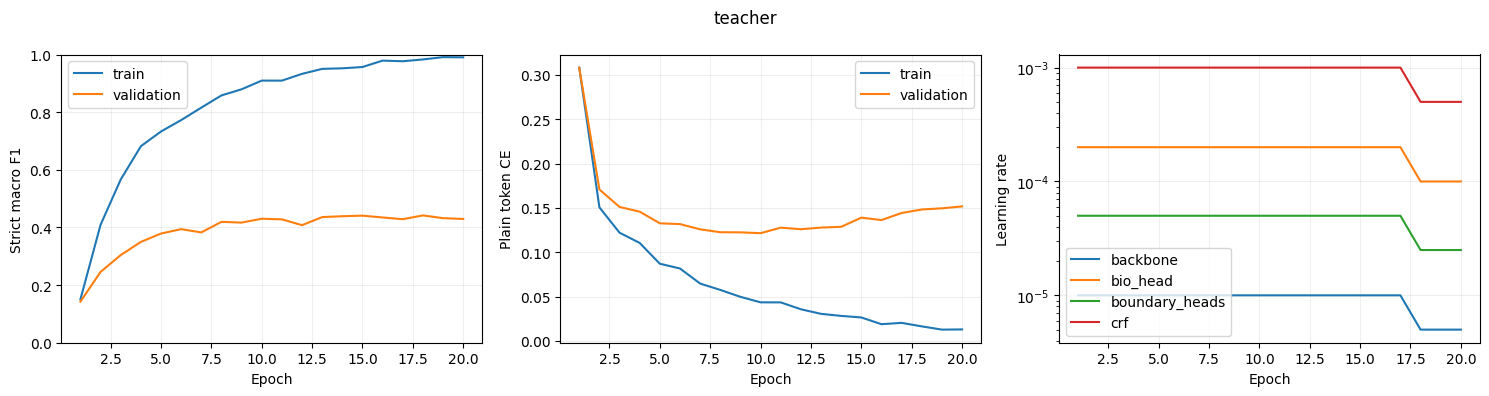

teacher best per-label strict F1: {'APP': 0.057, 'RESP': 0.132, 'A.COUNSEL': 0.667, 'R.COUNSEL': 0.548, 'JUDGE': 0.44, 'WIT': 0.087, 'AUTH': 0.073, 'COURT': 0.756, 'STAT': 0.669, 'PREC': 0.302, 'DATE': 0.943, 'CASENO': 0.627}


In [19]:
report = comparison_report(context)
import matplotlib.pyplot as plt
for kind in ("teacher", "baseline", "distilled"):
    run_dir = context["suite_dir"] / "runs" / kind
    history_path = run_dir / "history.json"
    if not history_path.exists():
        continue
    history = read_json(history_path)
    checks = [r for r in history if r.get("kind") == "validation" and r["epoch"] > 0]
    if not checks:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    epochs = [r["epoch"] for r in checks]
    axes[0].plot(epochs, [r["train_strict_macro_f1"] for r in checks], label="train")
    axes[0].plot(epochs, [r["strict_macro_f1"] for r in checks], label="validation")
    axes[0].set(xlabel="Epoch", ylabel="Strict macro F1", ylim=(0, 1))
    for part in ("train", "validation"):
        axes[1].plot(epochs, [r[part + "_losses"]["unweighted_tag_loss"] for r in checks], label=part)
    axes[1].set(xlabel="Epoch", ylabel="Plain token CE")
    for group in ("backbone", "bio_head", "boundary_heads", "crf"):
        axes[2].plot(epochs, [r["learning_rates_next_epoch"][group] for r in checks], label=group)
    axes[2].set(xlabel="Epoch", ylabel="Learning rate", yscale="log")
    for axis in axes:
        axis.legend(); axis.grid(alpha=0.2)
    fig.suptitle(kind); fig.tight_layout()
    fig.savefig(run_dir / "training_curves.png", dpi=160)
    plt.show()
    metrics = read_json(run_dir / "best_validation_metrics.json")
    print(kind, "best per-label strict F1:", {label: round(row["f1"], 3) for label, row in metrics["per_label"].items()})


## 6. CodaBench exports and diagnostic reports

The teacher, compact baseline and distilled student export separate ZIPs with
`prediction.json` at the root. The CodaBench table above reports the scored uploads.
The diagnostic archive records training histories, per-label results and run settings.


In [20]:
from IPython.display import display, FileLink
diagnostics = diagnostic_zip(context)
for path in sorted(ARTIFACT_ROOT.glob(SUITE_ID + "*_submission.zip")):
    display(FileLink(str(path.relative_to(ARTIFACT_ROOT))))
display(FileLink(str(diagnostics.relative_to(ARTIFACT_ROOT))))


/kaggle/working/efficient_ner_kd_001_diagnostics.zip

## 7. Resume backup

The suite backup keeps the selected checkpoints, compact LM recovery, shared
initialization and cached teacher scores. To resume in another session, attach the
original Phase 1 inputs and the suite backup. When the backup is split, keep
`manifest.json` and every part together.


In [21]:
backup_path = ARTIFACT_ROOT / f"{SUITE_ID}_backup.zip"
# The automatic backup was made before the optional plot cell. Rebuild once to include the plots.
if OPTIONS["make_backup"]:
    updated_backup = backup_suite(context)
    if updated_backup is not None:
        display(FileLink(str(updated_backup.relative_to(ARTIFACT_ROOT))))
        if updated_backup.name == "manifest.json":
            for part in sorted(updated_backup.parent.glob("*.bin")):
                display(FileLink(str(part.relative_to(ARTIFACT_ROOT))))
print("Preserve this whole folder:", context["suite_dir"])


Resumable suite backup: efficient_ner_kd_001_backup.zip | GiB 3.29
Download this manifest and EVERY .bin part: efficient_ner_kd_001_backup_parts_e1f85f6d95ab


/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/manifest.json

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part001.bin

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part002.bin

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part003.bin

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part004.bin

... (7 outputs left out)

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part012.bin

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part013.bin

/kaggle/working/efficient_ner_kd_001_backup_parts_e1f85f6d95ab/backup.part014.bin

Preserve this whole folder: /kaggle/working/cs781_phase2_efficient_kd/efficient_ner_kd_001


## References

- The [official CS781 dataset](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone) supplies the Phase 2 L-NER folds. The embedded `evaluate_phase2.py` scores exact start offset, end offset and label matches, then averages F1 across the 12 entity labels.
- Hinton et al. describe temperature-scaled targets and the temperature-squared loss factor. [Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531)
- Sanh et al. provide a precedent for initializing a shallower model from selected pretrained layers. [DistilBERT](https://arxiv.org/abs/1910.01108)
- Lample et al. describe neural sequence tagging with learned transition scores. [Neural Architectures for Named Entity Recognition](https://aclanthology.org/N16-1030/)
